# Numerai Classic v6.0 ("Unity") — MiniRocket Regressor (`NumeraiExtractions` + `MiniRocketNumeraiEstimator`)

- **Data Loading (`data_utils.load_unity_numerai_data_cached`)**: Resolves and downloads the Unity v6.0 Parquets using the official Kaggle clients (`kagglehub.dataset_download` and `kaggle.api.kaggle_api_extended.KaggleApi`) with `numerapi.NumerAPI` fallback, caches processed Parquets, and supports independent training & validation downsampling (`downsample_mode`/`downsample_frac` and `val_downsample_mode`/`val_downsample_frac`).
- **Exploratory Data Analysis (`# EDA`)**: Lists available `TARGET_COL` and `feature_set` options from `features.json`, inspects `train_df.head(2)` / `validation_df.head(2)` and `info()`, plots era sizes over time, overlays feature standard-deviation distributions across Train vs. Validation, and displays the top 10 features correlated with `TARGET_COL` along with ADF stationarity checks.

---

### 1. Feature Extraction Parameters (`utils.NumeraiExtractions` — `estimator__extractor__*`)
- Shared across `baseline_unity.ipynb`, `lightgbm_unity.ipynb`, and `minirocket_unity.ipynb` (correlation ranking, variance filtering, sparse selection, PCA, cross-sectional quantization, rolling-era & lag-diff statistics, per-ticker time-series features, and Fourier harmonics).

---

### 2. Shared Parent Estimator Parameters (`baseline_utils.BaseNumeraiEstimator` — `estimator__*`)
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`): How the estimator scores post-extraction features against `TARGET_COL` (used when `top_k` is set).
- **`abs_corr`** (`[True, False]`): `True` selects top features by $|\text{corr}|$; `False` selects by signed $\text{corr}$.
- **`top_k`** (`[None, 20, 40, 80]`): Number of top post-extraction features passed to MiniRocket (`None` uses all extracted features).
- **`era_weighting`** (`[None, 'equal_era', 'recency_linear', 'recency_exp']`): Computes per-row `sample_weight` passed into the linear head (`None`, equal weight per era, linear recency, or exponential recency decay).
- **`recency_decay`** (`Real(0.001, 0.020)`): Exponential decay rate per era when `era_weighting='recency_exp'`.
- **`prediction_transform`** (`[None, 'era_zscore', 'era_rank']`): Post-prediction within-era normalization (`None` = raw, `'era_zscore'`, or `'era_rank'`).
- **`bias_correction`** (`[None, 'mean_residual']`): When `'mean_residual'`, records `mean(y_train - y_hat_train)` in `fit()` and adds it to predictions in `predict()` (`None` disables).
- **Walk-Forward & Horizon Controls**: `walk_forward_step_eras`, `walk_forward_window`, `target_horizon_eras`, `era_stride`.

---

### 3. MiniRocket Model Parameters (`minirocket_utils.MiniRocketNumeraiEstimator` — `estimator__*`)
- **Sequence Construction**:
  - **`input_mode`** (`['ticker_sequence', 'feature_profile']`): `'ticker_sequence'` constructs a strictly causal multivariate `(C, seq_len)` sequence per `numerai_ticker` with a training tail buffer for leak-free validation warm-up; `'feature_profile'` applies univariate MiniRocket across each row's feature vector.
  - **`seq_len`** (`[9, 12, 16, 24]`): Causal lookback window length in eras (minimum `9` to match MiniRocket's length-9 kernels).
  - **`max_channels`** (`[8, 16, 32]`): Maximum top-ranked feature channels fed into multivariate MiniRocket.
  - **`pad_mode`** (`['first', 'neutral']`): Left-padding strategy for tickers with fewer than `seq_len` historical eras (`'first'` repeats earliest value; `'neutral'` pads with `2.0`).
- **MiniRocket Kernel & Dilation Bank (Dempster et al., 2021)**:
  - **`num_kernels`** (`[420, 840, 1680, 3360]`): Number of PPV features (rounded to a multiple of the 84 fixed length-9 `{-1, +2}` kernels).
  - **`max_dilations_per_kernel`** (`[4, 8, 16, 32]`): Maximum exponentially spaced dilations per base kernel.
  - **`fit_sample_size`** (`[1024, 2048, 4096]`): Training subsample size used to draw quantile biases.
  - **`backend`** (`['numpy', 'sktime', 'auto']`): Pure-NumPy vectorized Dempster-2021 MiniRocket (`'numpy'`, zero JIT cold-start & Kaggle-portable) or `sktime` Numba backend (`'sktime'` / `'auto'`).
- **OOM-Proof Batched Linear Head**:
  - **`standardize_features`** (`[True, False]`): Standardizes PPV features before fitting the linear head.
  - **`head_type`** (`['ridge_cv', 'ridge', 'sgd_elasticnet', 'sgd_huber']`): Single-pass batched analytical Ridge / RidgeCV (GCV) or batched SGD head (`elasticnet` / `huber`) — never materializes `(N, num_kernels)` in RAM.
  - **`alpha`** (`[1.0, 10.0, 100.0, 1000.0]` / `Real(1e-2, 1e5, prior='log-uniform')`): Regularization strength for `'ridge'` / SGD heads.
  - **`l1_ratio`** (`[0.05, 0.15, 0.5]` / `Real(0.0, 1.0)`): ElasticNet mixing parameter (active when `head_type='sgd_elasticnet'`).
  - **`huber_epsilon`** (`[1.1, 1.35, 1.75]` / `Real(1.05, 2.5)`): Huber outlier threshold (active when `head_type='sgd_huber'`).


In [1]:
import gc
import os
import sys
import json
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

python_env_dir = Path(sys.executable).parent
library_bin_dir = python_env_dir / 'Library' / 'bin'
if library_bin_dir.is_dir() and str(library_bin_dir) not in os.environ.get('PATH', ''):
    os.environ['PATH'] = str(library_bin_dir) + os.pathsep + str(python_env_dir) + os.pathsep + os.environ.get('PATH', '')

import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
try:
    import seaborn as sns
except ImportError:
    sns = None
from IPython.display import display

warnings.filterwarnings('ignore')

# Local, Kaggle (/kaggle/input, /kaggle/usr/lib, /kaggle/working), & nested dataset path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
if workspace_root not in sys.path:
    sys.path.insert(0, workspace_root)
if os.path.isdir(src_path) and src_path not in sys.path:
    sys.path.insert(0, src_path)

module_search_roots = [
    Path(workspace_root),
    Path('/kaggle/working'),
    Path('/kaggle/usr/lib'),
    Path('/kaggle/input'),
]
for search_root in module_search_roots:
    if not search_root.is_dir():
        continue
    for target_file in ('afml_utils.py', 'data_utils.py', 'utils.py', 'baseline_utils.py', 'minirocket_utils.py'):
        for found_path in search_root.rglob(target_file):
            parent_dir = str(found_path.parent)
            if parent_dir not in sys.path:
                sys.path.insert(0, parent_dir)

from pandas.plotting import autocorrelation_plot
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from statsmodels.graphics.gofplots import qqplot

from numerai_tools.scoring import numerai_corr

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

try:
    import wandb
except ImportError:
    wandb = None

try:
    import afml_utils
    import data_utils
    import utils
    import baseline_utils
    import minirocket_utils
except ModuleNotFoundError as import_err:
    mounted_kaggle_inputs = [str(p) for p in sorted(Path('/kaggle/input').iterdir())] if Path('/kaggle/input').is_dir() else []
    raise ModuleNotFoundError(
        f"{import_err}. Could not locate data_utils.py / utils.py / baseline_utils.py / minirocket_utils.py in "
        f"workspace_root={workspace_root}, /kaggle/working, /kaggle/usr/lib, or /kaggle/input "
        f"(mounted inputs: {mounted_kaggle_inputs}). "
        "On Kaggle, attach a Dataset or Utility Script containing src/data_utils.py, src/utils.py, src/baseline_utils.py, and src/minirocket_utils.py."
    ) from import_err
importlib.reload(afml_utils)
importlib.reload(data_utils)
importlib.reload(utils)
importlib.reload(baseline_utils)
importlib.reload(minirocket_utils)
from data_utils import (
    compute_per_ticker_timeseries_features,
    discover_and_fetch_v6_meta_or_benchmark,
    load_unity_numerai_data,
    load_unity_numerai_data_cached,
)
from utils import (
    NumeraiExtractions,
    build_experiment_setup,
    build_conditional_bayesian_spaces,
    build_quick_results_df,
    candidate_score,
    compute_eda_era_stationarity,
    compute_era_error_envelope,
    configure_error_binning,
    compute_feature_exposure,
    compute_feature_target_correlations,
    compute_per_era_mmc,
    compute_per_era_numerai_corr,
    compute_per_era_spearman_corr,
    deduplicate_param_grid,
    drop_constant_dims,
    evaluate_numerai_predictions,
    export_diagnostics_predictions,
    plot_era_error_envelope,
    plot_residual_diagnostics,
    plot_stake_pnl_dashboard,
    plot_stake_pnl_monte_carlo,
    prepare_bayesian_space,
    prepare_tuned_pipeline,
    quantize_to_5bins,
    reset_cv_metric_log,
    sharpe_ratio,
    simulate_stake_pnl,
    simulate_stake_pnl_monte_carlo,
    build_live_staking_scenarios_df,
    compute_deflated_sharpe_ratio,
    compute_probabilistic_sharpe_ratio,
    run_numereval_diagnostics,
    simulate_live_staking_scenarios,
    walk_forward_predict,
    CombinatorialPurgedEraCV,
    PurgedEraKFold,
    build_era_cv_splits,
    compute_clustered_mda,
    compute_drawdown_and_tuw,
    compute_hhi_concentration,
    compute_lo_adjusted_sharpe,
    compute_min_track_record_length,
    compute_pbo_cscv,
    compute_per_era_fnc,
    compute_r1399_churn_retention,
    compute_strategy_risk,
    compute_versioned_candidate_score,
    make_candidate_scorer,
    neutralize_predictions,
    purge_train_before_validation,
    summarize_afml_backtest_diagnostics,
    build_compact_afml_reference_table,
    build_diagnostics_summary_table,
    build_executive_scorecard_tables,
    plot_candidate_timing_analysis,
    display_compact_dataframe,
    export_winner_scorecard_json,
    plot_afml_backtest_story,
    plot_cumulative_validation_corr,
    plot_rolling_validation_corr,
    plot_top2_residuals_vs_actual,
    build_afml_diagnostics_df,
    strip_validation_predictions,
)
from baseline_utils import (
    BaseNumeraiEstimator,
    clear_extraction_cache,
    configure_extraction_cache,
    display_top_cv_candidates,
    extract_cv_analysis_artifacts,
)
from minirocket_utils import (
    MiniRocketNumeraiEstimator,
    SKTIME_MINIROCKET_AVAILABLE,
    display_minirocket_interpretability,
    extract_minirocket_interpretability,
)

print('Imports loaded successfully')
print(f'workspace_root={workspace_root} | SKOPT_AVAILABLE={SKOPT_AVAILABLE} | SKTIME_MINIROCKET_AVAILABLE={SKTIME_MINIROCKET_AVAILABLE}')

Imports loaded successfully
workspace_root=/kaggle/working | SKOPT_AVAILABLE=True | SKTIME_MINIROCKET_AVAILABLE=False


# Setup

In [2]:
# --- Experiment Knobs (only things you actually change) ---
TARGET_COL = 'target'          # Training target (auto-sets horizon & embargo)
feature_set = 'small'          # 'small', 'medium', or 'all'
era_stride = 'auto'            # 'auto' (matches target horizon: 12 for 60d, 4 for 20d) or explicit int (1, 2, 4, 12)

search_mode = 'bayes'          # 'grid' or 'bayes'
score_version = 'v1_skepta'    # 'v0_default', 'v1_skepta', or 'v2_skepta_mmc'
eval_mode = 'both'             # Default=static only; Tuned walk-forward at end
walk_forward_step_eras = 52    # Annual refit (~8 refits over 399 val eras; applied to [Tuned] winner)
cv_strategy = 'timeseries'   # 'timeseries', 'purged_kfold' (AFML Ch. 7), or 'cpcv' (AFML Ch. 12)
n_splits = 1
cv_split = 0.8                 # Chronological CV train/test split ratio (used when n_splits == 1)
downsample_mode = 'recent'         # None, 'recent', 'earliest', or 'uniform'
downsample_frac = 0.01          # Fraction of strided training data to keep in (0.0, 1.0]
val_downsample_mode = 'recent'     # Validation: None (100%), 'same', 'recent', 'earliest', or 'uniform'
val_downsample_frac = 0.01             # Fraction of validation data to keep in (0.0, 1.0] (None mirrors downsample_frac)
n_iter = 1
n_jobs = -1                    # Worker thread count (inner CV stays 1 to avoid RAM duplication)
save_results = True
save_plots = False             # Save PNG plots to workspace (CSV/JSON still controlled by save_results)
memory_guard_enabled = True    # Explicit RAM fail-safe: set False to switch off
memory_guard_min_free_gb = 3.0 # Keep >=3 GB free RAM or fail candidate with error_score=-1.0
time_guard_enabled = True      # Explicit per-candidate wall-clock fail-safe: set False to switch off
max_candidate_seconds = 1200.0 # Abort slow candidate after 30 min (1800s) with error_score=-1.0
error_bin_mode = 'pct'         # 'pct' (% error + zero-target tol) or 'abs' (raw residual bins)

setup_cfg = build_experiment_setup(
    target_col=TARGET_COL,
    feature_set=feature_set,
    era_stride=era_stride,
    model_tag='minirocket',
    search_mode=search_mode,
    score_version=score_version,
    eval_mode=eval_mode,
    walk_forward_step_eras=walk_forward_step_eras,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    n_iter=n_iter,
    n_jobs=1,
    lgbm_n_jobs=n_jobs,
    save_results=save_results,
    save_plots=save_plots,
    memory_guard_enabled=memory_guard_enabled,
    memory_guard_min_free_gb=memory_guard_min_free_gb,
    time_guard_enabled=time_guard_enabled,
    max_candidate_seconds=max_candidate_seconds,
    error_bin_mode=error_bin_mode,
    workspace_root=workspace_root,
    wandb_project='numerai-minirocket',
)
globals().update(setup_cfg)

Experiment: numerai_v6.0_all_eras_stride12_minirocket | model=minirocket | search_mode=bayes | cv_strategy=timeseries (cv_split=0.8) | ERA_COL=era | TARGET_COL=target | era_stride=12 (auto-matched to horizon=12) | horizon=12 | embargo=1 | downsample(train=recent@0.01, val=recent@0.01)


# Prep

In [3]:
_prep_t0 = time.perf_counter()
train_df, validation_df, feature_columns, feature_metadata = load_unity_numerai_data_cached(
    data_version=data_version,
    data_folder=data_folder,
    kaggle_dataset=kaggle_dataset,
    feature_set=feature_set,
    target_col=TARGET_COL,
    era_stride=era_stride,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    random_state=random_state,
    ticker_timeseries_features=ticker_timeseries_features,
    ticker_rolling_windows=ticker_rolling_windows,
    ticker_lag_steps=ticker_lag_steps,
    workspace_root=workspace_root,
    auto_download=True,
    use_numerapi_fallback=True,
    force_reload=force_reload_data_cache,
)
prep_elapsed_s = time.perf_counter() - _prep_t0
print(f'Loaded {len(feature_columns)} int8 features | train={train_df.shape} ({train_df[ERA_COL].nunique()} eras) | validation={validation_df.shape} ({validation_df[ERA_COL].nunique()} eras)')

Loaded 101 int8 features | train=(12854, 106) (2 eras) | validation=(28498, 106) (4 eras)


## Exploratory Data Analysis (EDA)

In [4]:
available_targets = list(feature_metadata.get('targets', [TARGET_COL]))
print(f'Available TARGET_COL options ({len(available_targets)}):', available_targets)
print('Available feature_set options:', {k: len(v) for k, v in feature_metadata.get('feature_sets', {}).items()})

print('\nTraining data:')
display(train_df.head(2))
print('Validation data:')
display(validation_df.head(2))
print('Training set info:')
train_df.info()
print('\nValidation set info:')
validation_df.info()

Available TARGET_COL options (24): ['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
Available feature_set options: {'small': 101, 'medium': 351, 'all': 1040, 'signals': 23}

Training data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_41,feature_charisma_2,feature_charisma_5,feature_charisma_7,feature_charisma_11,feature_charisma_13,...,feature_wisdom_67,feature_wisdom_75,feature_wisdom_78,feature_wisdom_96,feature_endurance_7,feature_endurance_13,feature_endurance_69,feature_country,target,era
0,2018-08-24,train,000030 KR,2,2,4,3,3,1,4,...,0,3,2,3,3,4,3,2,0.5,817
1,2018-08-24,train,000060 KR,2,2,3,4,4,1,1,...,2,3,3,3,0,4,3,2,0.5,817


Validation data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_41,feature_charisma_2,feature_charisma_5,feature_charisma_7,feature_charisma_11,feature_charisma_13,...,feature_wisdom_67,feature_wisdom_75,feature_wisdom_78,feature_wisdom_96,feature_endurance_7,feature_endurance_13,feature_endurance_69,feature_country,target,era
0,2026-07-31,validation,000080 KR,2,1,0,0,0,0,3,...,3,3,4,1,0,4,1,2,0.50,1231
1,2026-07-31,validation,000100 KR,2,2,1,4,1,1,3,...,0,3,2,1,2,4,0,2,0.75,1231


Training set info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12854 entries, 0 to 12853
Columns: 106 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(101), object(2)
memory usage: 1.6+ MB

Validation set info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28498 entries, 0 to 28497
Columns: 106 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(101), object(2)
memory usage: 3.6+ MB


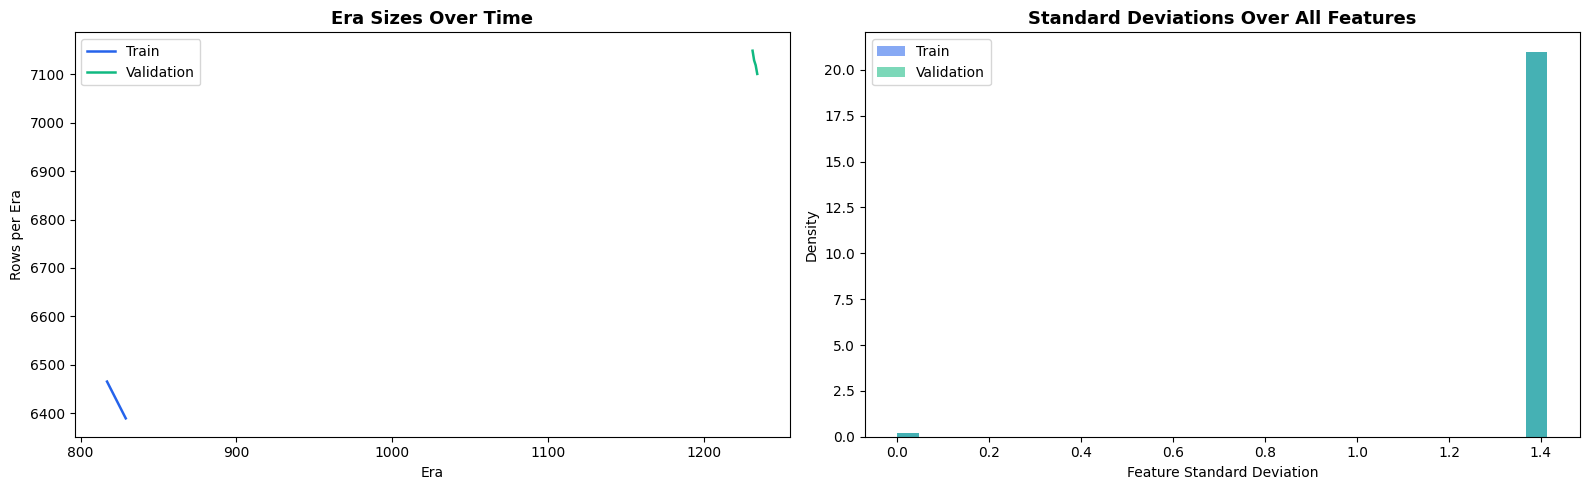

Top 10 Features according to absolute correlation with target:


feature_charisma_7          0.021771
feature_dexterity_14        0.021648
feature_wisdom_53           0.019618
feature_charisma_147        0.019557
feature_constitution_45     0.018511
feature_constitution_308    0.018081
feature_constitution_318    0.017896
feature_strength_65         0.017835
feature_strength_28         0.016974
feature_constitution_299    0.016789
dtype: float64

ADF Stationarity Check on Top 10 Features (Per-Era Means):


,feature,adf_stat,adf_pvalue,stationary_at_5pct
0,feature_charisma_7,0.0,1.0,False
1,feature_dexterity_14,0.0,1.0,False
2,feature_wisdom_53,0.0,1.0,False
3,feature_charisma_147,0.0,1.0,False
4,feature_constitution_45,0.0,1.0,False
5,feature_constitution_308,0.0,1.0,False
6,feature_constitution_318,0.0,1.0,False
7,feature_strength_65,0.0,1.0,False
8,feature_strength_28,0.0,1.0,False
9,feature_constitution_299,0.0,1.0,False


10381

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

train_era_sizes = train_df.groupby(ERA_COL)[TARGET_COL].size()
val_era_sizes = validation_df.groupby(ERA_COL)[TARGET_COL].size()
axes[0].plot(train_era_sizes.index, train_era_sizes.to_numpy(), color='#2563eb', linewidth=1.8, label='Train')
axes[0].plot(val_era_sizes.index, val_era_sizes.to_numpy(), color='#10b981', linewidth=1.8, label='Validation')
axes[0].set_title('Era Sizes Over Time', weight='bold', fontsize=13)
axes[0].set_xlabel('Era')
axes[0].set_ylabel('Rows per Era')
axes[0].legend()

train_feat_stds = train_df[feature_columns].std()
val_feat_stds = validation_df[feature_columns].std()
axes[1].hist(train_feat_stds, bins=30, alpha=0.55, density=True, color='#2563eb', label='Train')
axes[1].hist(val_feat_stds, bins=30, alpha=0.55, density=True, color='#10b981', label='Validation')
axes[1].set_title('Standard Deviations Over All Features', weight='bold', fontsize=13)
axes[1].set_xlabel('Feature Standard Deviation')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

corr_with_target = train_df[feature_columns].corrwith(train_df[TARGET_COL]).abs().sort_values(ascending=False)
print('Top 10 Features according to absolute correlation with target:')
display(corr_with_target.head(10))

eda_stationarity_df = compute_eda_era_stationarity(train_df, list(corr_with_target.head(10).index), era_col=ERA_COL)
print('ADF Stationarity Check on Top 10 Features (Per-Era Means):')
display(eda_stationarity_df)
plt.close(fig)
del fig, axes, train_era_sizes, val_era_sizes, train_feat_stds, val_feat_stds, corr_with_target, eda_stationarity_df
gc.collect()

In [6]:
input_columns = [ERA_COL] + ([TICKER_COL] if TICKER_COL in train_df.columns and TICKER_COL in validation_df.columns else []) + feature_columns
X_train = train_df[input_columns].reset_index(drop=True)
y_train = train_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
train_eras = train_df[ERA_COL].astype(np.int32).reset_index(drop=True)

X_validation = validation_df[input_columns].reset_index(drop=True)
y_validation = validation_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
validation_eras = validation_df[ERA_COL].astype(np.int32).reset_index(drop=True)

# Retain only lightweight validation metadata for diagnostics export, date-aware staking, and free raw DataFrames
val_diag_meta = validation_df[[c for c in ('id', 'numerai_ticker', 'date', ERA_COL) if c in validation_df.columns]].reset_index(drop=True).copy()
val_era_dates = (
    val_diag_meta.groupby(ERA_COL, sort=True)['date'].first()
    if ('date' in val_diag_meta.columns and ERA_COL in val_diag_meta.columns)
    else None
)
del train_df, validation_df
gc.collect()

# Era-level purged CV splitter supporting 'timeseries', 'purged_kfold' (AFML Ch. 7), and 'cpcv' (AFML Ch. 12)
cv_object = build_era_cv_splits(
    train_eras,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    target_horizon_eras=target_horizon_eras,
    embargo_eras=embargo_eras,
)
print(
    f'Built {len(cv_object)} strictly era-purged CV fold(s) using cv_strategy={cv_strategy!r} '
    f'(horizon={target_horizon_eras} eras, embargo={embargo_eras} eras)'
)


Built 1 strictly era-purged CV fold(s) using cv_strategy='timeseries' (horizon=12 eras, embargo=1 eras)


In [7]:
raw_feature_sets = feature_metadata.get('feature_sets', {})
meta_set_names = {'small', 'medium', 'all'}
active_feature_set_cols = set(feature_columns)
unity_feature_groups_dict = {
    group_name: tuple(col for col in group_cols if col in active_feature_set_cols)
    for group_name, group_cols in raw_feature_sets.items()
    if group_name not in meta_set_names and isinstance(group_cols, list)
}
unity_feature_groups_dict = {k: v for k, v in unity_feature_groups_dict.items() if len(v) >= 2}
unity_feature_groups = tuple(sorted(unity_feature_groups_dict.items())) if unity_feature_groups_dict else None

numerai_extractions = NumeraiExtractions(
    era_col=ERA_COL,
    target_col=TARGET_COL,
    ticker_col=TICKER_COL,
    year_horizon_filter=None,
    variance_threshold=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    top_k=None,
    feature_selection_percentile=None,
    sparse_selector=None,
    sparse_alpha=0.01,
    pca_n_components=None,
    quantize_scope='era',
    quantize_strategy='zscore',
    sequence_top_n=4,
    feature_groups=unity_feature_groups,
    basic_group_stats=None,
    fourier_period_eras=52,
    fourier_order=None,
    rolling_era_windows=(4, 12),
    include_rolling_era=False,
    era_lag_scales=(1, 2, 4),
    include_lag_diff=False,
    ticker_features=None,
    ticker_windows=(4, 12),
    ticker_lag_steps=None,
    era_dispersion_features=None,
    missing_fill_value=2.0,
)

minirocket_estimator = MiniRocketNumeraiEstimator(
    extractor=clone(numerai_extractions),
    # BaseNumeraiEstimator shared params
    top_k=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    ticker_col=TICKER_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
    # MiniRocket sequence & kernel bank params
    input_mode='ticker_sequence',
    seq_len=12,
    max_channels=16,
    pad_mode='first',
    num_kernels=840,
    max_dilations_per_kernel=8,
    fit_sample_size=2048,
    backend='numpy',
    # Batched linear head params
    standardize_features=True,
    head_type='ridge_cv',
    alpha=100.0,
    l1_ratio=0.15,
    huber_epsilon=1.35,
    batch_size=16384,
    n_jobs=lgbm_n_jobs,
)

minirocket_pipeline = Pipeline([('estimator', minirocket_estimator)])
print('MiniRocket pipeline ready:', minirocket_pipeline)
del feature_metadata, raw_feature_sets
gc.collect()

MiniRocket pipeline ready: Pipeline(steps=[('estimator',
                 MiniRocketNumeraiEstimator(extractor=NumeraiExtractions(),
                                            target_horizon_eras=12,
                                            verbose=3))])


0

# Params

## Grid

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [8]:
# SHARED `NumeraiExtractions` GRID SPACE
GRID_EXTRACTOR_PARAM_SPACE = {
    # ----------------------------------------------------------
    # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
    # ----------------------------------------------------------
    'estimator__extractor__era_col': [ERA_COL],
    'estimator__extractor__ticker_col': [TICKER_COL],
    'estimator__extractor__target_col': [
        TARGET_COL,
        # 'target_cyrusd_20',
        # 'target_teager2b_20',
    ],
    'estimator__extractor__year_horizon_filter': [
        None,
        # (1, 2, 3),
        # (4, 5, 6),
        # (7, 8, 9),
    ],
    'estimator__extractor__variance_threshold': [
        None,
        # 0.02,
        # 0.05,
        # 0.10,
    ],
    'estimator__extractor__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__extractor__abs_corr': [
        True,
        # False,
    ],
    'estimator__extractor__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__extractor__feature_selection_percentile': [
        None,
        # 25.0,
        # 50.0,
        # 75.0,
        # 100.0,
    ],
    'estimator__extractor__sparse_selector': [
        None,
        # 'lasso',
        # 'elasticnet',
    ],
    'estimator__extractor__sparse_alpha': [
        0.01,
        # 0.001,
        # 0.1,
    ],
    'estimator__extractor__pca_n_components': [
        None,
        # 10,
        # 20,
        # 0.90,
    ],
    'estimator__extractor__quantize_scope': [
        'era',
        # 'train_fit',
        # 'global',
    ],
    'estimator__extractor__quantize_strategy': [
        'zscore',
        # 'quantile',
    ],
    'estimator__extractor__sequence_top_n': [
        4,
        # 2,
        # 8,
    ],
    'estimator__extractor__missing_fill_value': [
        2.0,
        # 0.0,
        # 4.0,
        # 'mean',
        # 'median',
        # 'era_mean',
        # 'era_median',
    ],

    # ----------------------------------------------------------
    # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
    # ----------------------------------------------------------
    'estimator__extractor__basic_group_stats': [
        None,
        # 'mean',
        # 'std',
        # 'skew',
        # 'mean|std',
        # 'mean|skew',
        # 'std|skew',
        # 'mean|std|skew',
    ],
    'estimator__extractor__fourier_period_eras': [
        52,
        # 26,
        # 13,
    ],
    'estimator__extractor__fourier_order': [
        None,
        # 1,
        # 2,
        # 3,
    ],
    'estimator__extractor__rolling_era_windows': [
        (4, 12),
        # (2, 6, 12),
        # (4, 8, 16),
    ],
    'estimator__extractor__include_rolling_era': [
        False,
        # True,
    ],
    'estimator__extractor__era_lag_scales': [
        (1, 2, 4),
        # (1, 2, 4, 8),
        # (2, 4, 8),
    ],
    'estimator__extractor__include_lag_diff': [
        False,
        # True,
    ],
    'estimator__extractor__ticker_features': [
        None,
        # 'rolling_mean',
        # 'momentum_diff',
        # 'weeks_since_high',
        # 'rolling_rank',
        # 'weeks_since_change',
        # 'expanding_stats',
        # 'raw_lags',
        # 'rolling_mean|momentum_diff',
        # 'rolling_mean|momentum_diff|rolling_rank',
        # 'expanding_stats|raw_lags',
        # 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
    ],
    'estimator__extractor__ticker_windows': [
        (4, 12),
        # (2, 6, 12),
    ],
    'estimator__extractor__ticker_lag_steps': [
        None,
        # (1, 2),
        # (1, 2, 4),
    ],
    'estimator__extractor__era_dispersion_features': [
        None,
        # 'mean',
        # 'std',
        # 'extreme_frac',
        # 'mean|std',
        # 'mean|extreme_frac',
        # 'std|extreme_frac',
        # 'mean|std|extreme_frac',
    ],
}

### MiniRocket Model Params (`MiniRocketNumeraiEstimator`)

In [9]:
GRID_PARAM_SPACE_MINIROCKET = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # SHARED PARENT — BaseNumeraiEstimator Wrapper Controls
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__ticker_col': [TICKER_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__top_k': [
        None,
        # 20,
        # 40,
        # 80,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
        # 'uniqueness',
        # 'uniqueness_decay',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],

    # ----------------------------------------------------------
    # MODEL — MiniRocket Sequence & Kernel Bank
    # ----------------------------------------------------------
    'estimator__input_mode': [
        'ticker_sequence',
        # 'feature_profile',
    ],
    'estimator__seq_len': [
        12,
        # 9,
        # 16,
        # 24,
    ],
    'estimator__max_channels': [
        16,
        # 8,
        # 32,
    ],
    'estimator__pad_mode': [
        'first',
        # 'neutral',
    ],
    'estimator__num_kernels': [
        840,
        # 420,
        # 1680,
        # 3360,
    ],
    'estimator__max_dilations_per_kernel': [
        8,
        # 4,
        # 16,
        # 32,
    ],
    'estimator__fit_sample_size': [
        2048,
        # 1024,
        # 4096,
    ],
    'estimator__backend': [
        'numpy',
        # 'sktime',
        # 'auto',
    ],

    # ----------------------------------------------------------
    # MODEL — Batched Linear Head
    # ----------------------------------------------------------
    'estimator__standardize_features': [
        True,
        # False,
    ],
    'estimator__head_type': [
        'ridge_cv',
        # 'ridge',
        # 'sgd_elasticnet',
        # 'sgd_huber',
    ],
    'estimator__alpha': [
        100.0,
        # 1.0,
        # 10.0,
        # 1000.0,
    ],
    'estimator__l1_ratio': [
        0.15,
        # 0.05,
        # 0.5,
    ],
    'estimator__huber_epsilon': [
        1.35,
        # 1.1,
        # 1.75,
    ],
    'estimator__n_jobs': [lgbm_n_jobs],
}
print(f'GRID_PARAM_SPACE_MINIROCKET keys={len(GRID_PARAM_SPACE_MINIROCKET)}')

GRID_PARAM_SPACE_MINIROCKET keys=57


## Bayesian

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [10]:
# BAYESIAN SEARCH ONLY — Shared `BAYESIAN_EXTRACTOR_PARAM_SPACE`
# Mode/selection parameters start with `None` (off); boolean `include_*` flags use `[False, True]`.
BAYESIAN_EXTRACTOR_PARAM_SPACE = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_EXTRACTOR_PARAM_SPACE = {
        # ----------------------------------------------------------
        # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
        # ----------------------------------------------------------
        'estimator__extractor__era_col': Categorical([ERA_COL]),
        'estimator__extractor__ticker_col': Categorical([TICKER_COL]),
        'estimator__extractor__target_col': Categorical([
            TARGET_COL,
        ]),
        'estimator__extractor__year_horizon_filter': Categorical([
            None,
            (1, 2, 3),
            (4, 5, 6),
            (7, 8, 9),
        ]),
        'estimator__extractor__variance_threshold': Categorical([
            None,
            0.02,
            0.05,
            0.10,
        ]),
        'estimator__extractor__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__extractor__abs_corr': Categorical([True, False]),
        'estimator__extractor__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__feature_selection_percentile': Categorical([
            None,
            25.0,
            50.0,
            75.0,
            100.0,
        ]),
        'estimator__extractor__sparse_selector': Categorical([
            None,
            'lasso',
            'elasticnet',
        ]),
        'estimator__extractor__sparse_alpha': Real(1e-4, 1e-1, prior='log-uniform'),
        'estimator__extractor__pca_n_components': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__quantize_scope': Categorical([
            'era',
            'train_fit',
            'global',
        ]),
        'estimator__extractor__quantize_strategy': Categorical([
            'zscore',
            'quantile',
        ]),
        'estimator__extractor__sequence_top_n': Categorical([
            2,
            4,
            8,
        ]),
        'estimator__extractor__missing_fill_value': Categorical([
            2.0,
            0.0,
            4.0,
            'mean',
            'median',
            'era_mean',
            'era_median',
        ]),

        # ----------------------------------------------------------
        # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
        # ----------------------------------------------------------
        'estimator__extractor__basic_group_stats': Categorical([
            None,
            'mean',
            'std',
            'skew',
            'mean|std',
            'mean|skew',
            'std|skew',
            'mean|std|skew',
        ]),
        'estimator__extractor__fourier_period_eras': Categorical([
            52,
            26,
            13,
        ]),
        'estimator__extractor__fourier_order': Categorical([
            None,
            1,
            2,
            3,
        ]),
        'estimator__extractor__rolling_era_windows': Categorical([
            (4, 12),
            (2, 6, 12),
            (4, 8, 16),
        ]),
        'estimator__extractor__include_rolling_era': Categorical([False, True]),
        'estimator__extractor__era_lag_scales': Categorical([
            (1, 2, 4),
            (1, 2, 4, 8),
            (2, 4, 8),
        ]),
        'estimator__extractor__include_lag_diff': Categorical([False, True]),
        'estimator__extractor__ticker_features': Categorical([
            None,
            'rolling_mean',
            'momentum_diff',
            'weeks_since_high',
            'rolling_rank',
            'weeks_since_change',
            'expanding_stats',
            'raw_lags',
            'rolling_mean|momentum_diff',
            'rolling_mean|momentum_diff|rolling_rank',
            'expanding_stats|raw_lags',
            'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
        ]),
        'estimator__extractor__ticker_windows': Categorical([
            (4, 12),
            (2, 6, 12),
        ]),
        'estimator__extractor__ticker_lag_steps': Categorical([
            None,
            (1, 2),
            (1, 2, 4),
        ]),
        'estimator__extractor__era_dispersion_features': Categorical([
            None,
            'mean',
            'std',
            'extreme_frac',
            'mean|std',
            'mean|extreme_frac',
            'std|extreme_frac',
            'mean|std|extreme_frac',
        ]),
    }

### MiniRocket Model Params (`MiniRocketNumeraiEstimator`)

In [11]:
BAYESIAN_PARAM_SPACE_MINIROCKET = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_PARAM_SPACE_MINIROCKET = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # SHARED PARENT — BaseNumeraiEstimator Wrapper Controls
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__ticker_col': Categorical([TICKER_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__top_k': Categorical([
            None,
            20,
            40,
            80,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([None]),
        'estimator__walk_forward_window': Categorical([walk_forward_window]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
            'uniqueness',
            'uniqueness_decay',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),

        # ----------------------------------------------------------
        # MODEL — MiniRocket Sequence & Kernel Bank
        # ----------------------------------------------------------
        'estimator__input_mode': Categorical(['ticker_sequence', 'feature_profile']),
        'estimator__seq_len': Categorical([9, 12, 16, 24]),
        'estimator__max_channels': Categorical([8, 16, 32]),
        'estimator__pad_mode': Categorical(['first', 'neutral']),
        'estimator__num_kernels': Integer(84, 5000),
        'estimator__max_dilations_per_kernel': Categorical([4, 8, 16, 32]),
        'estimator__fit_sample_size': Categorical([1024, 2048, 4096]),
        'estimator__backend': Categorical(['numpy']),

        # ----------------------------------------------------------
        # MODEL — Batched Linear Head
        # ----------------------------------------------------------
        'estimator__standardize_features': Categorical([True, False]),
        'estimator__head_type': Categorical(['ridge_cv', 'ridge', 'sgd_elasticnet', 'sgd_huber']),
        'estimator__alpha': Real(1e-2, 1e5, prior='log-uniform'),
        'estimator__l1_ratio': Real(0.0, 1.0),
        'estimator__huber_epsilon': Real(1.05, 2.5),
        'estimator__n_jobs': Categorical([lgbm_n_jobs]),
    }
    BAYESIAN_PARAM_SPACE_MINIROCKET = prepare_bayesian_space(BAYESIAN_PARAM_SPACE_MINIROCKET)
print(f'BAYESIAN_PARAM_SPACE_MINIROCKET keys={len(BAYESIAN_PARAM_SPACE_MINIROCKET)}')

BAYESIAN_PARAM_SPACE_MINIROCKET keys=57


## Active Search Space Validation & Routing

In [12]:
minirocket_param_names = set(minirocket_pipeline.get_params(deep=True))
expected_tunable_params = {
    p for p in minirocket_param_names
    if p.startswith('estimator__') and p not in ('estimator__extractor', 'estimator__extractor__feature_groups', 'estimator__batch_size')
}
assert set(GRID_PARAM_SPACE_MINIROCKET).issubset(minirocket_param_names)
assert expected_tunable_params == set(GRID_PARAM_SPACE_MINIROCKET), (
    f'Missing from GRID_PARAM_SPACE_MINIROCKET: {sorted(expected_tunable_params - set(GRID_PARAM_SPACE_MINIROCKET))}'
)
if SKOPT_AVAILABLE:
    assert set(BAYESIAN_PARAM_SPACE_MINIROCKET).issubset(minirocket_param_names)
    assert expected_tunable_params == set(BAYESIAN_PARAM_SPACE_MINIROCKET), (
        f'Missing from BAYESIAN_PARAM_SPACE_MINIROCKET: {sorted(expected_tunable_params - set(BAYESIAN_PARAM_SPACE_MINIROCKET))}'
    )

if search_mode == 'bayes':
    _pruned_mr_bayes = drop_constant_dims(BAYESIAN_PARAM_SPACE_MINIROCKET, minirocket_pipeline)
    minirocket_param_space = build_conditional_bayesian_spaces(_pruned_mr_bayes, total_n_iter=n_iter)
else:
    minirocket_param_space = GRID_PARAM_SPACE_MINIROCKET
_active_dim_count = len(set().union(*(sub.keys() for sub, _ in minirocket_param_space))) if isinstance(minirocket_param_space, list) else len(minirocket_param_space)
print(f'Active search_mode={search_mode} | Active MiniRocket + Extractor dims={_active_dim_count} (total exposed={len(expected_tunable_params)})')


Active search_mode=bayes | Active MiniRocket + Extractor dims=43 (total exposed=57)


# Train

In [13]:
_train_t0 = time.perf_counter()
model_results = {}
search_summary_rows = []
cv_results_by_model = {}
fitted_default_models = {}

_feat_tier = str(feature_set).strip().lower()
effective_cache_max_entries = (
    min(int(extraction_cache_max_entries), 1)
    if _feat_tier == 'all'
    else (min(int(extraction_cache_max_entries), 2) if _feat_tier == 'medium' else int(extraction_cache_max_entries))
)
configure_extraction_cache(enabled=extraction_cache_enabled, max_entries=effective_cache_max_entries)

model_name = 'MiniRocket Regressor'
print(
    f'Running {model_name} inline (n_jobs={lgbm_n_jobs}, inner cv_n_jobs=1, '
    f'score_version={score_version}, extraction_cache_max_entries={effective_cache_max_entries})'
)

# AFML Ch. 7.4.1: Purge trailing training eras overlapping the start of validation before static fits
X_train_static, y_train_static, train_eras_static, static_purge_info = purge_train_before_validation(
    X_train,
    y_train,
    train_eras,
    validation_eras,
    target_horizon_eras=target_horizon_eras,
)
if static_purge_info['n_eras_purged'] > 0:
    print(
        f"  [AFML Purge | {model_name}] Purged {static_purge_info['n_eras_purged']} trailing train era(s) "
        f"(cutoff <= era {static_purge_info['cutoff_era']}, min_val_era={static_purge_info['min_val_era']}, "
        f"horizon={target_horizon_eras}) before static validation fits."
    )

default_model = clone(minirocket_pipeline).fit(X_train_static, y_train_static)
fitted_default_models[model_name] = default_model

train_preds = default_model.predict(X_train_static)
val_preds = default_model.predict(X_validation)

train_eval = evaluate_numerai_predictions(
    y_train_static,
    train_preds,
    eras=train_eras_static,
    features_df=X_train_static,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Training Scores',
    verbose=True,
)
val_eval = evaluate_numerai_predictions(
    y_validation,
    val_preds,
    eras=validation_eras,
    features_df=X_validation,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Validation Scores',
    verbose=True,
)

default_variant_name = f'{model_name} [Default]'
if eval_mode in ('static', 'both'):
    val_pnl = simulate_stake_pnl(val_eval['numerai_era_corrs'], era_dates=val_era_dates)
    val_dsr_info = compute_deflated_sharpe_ratio(val_eval['numerai_era_corrs'], [val_eval['numerai_sharpe']])
    model_results[default_variant_name] = {
        'variant': default_variant_name,
        'score_version': str(score_version),
        'train_corr': train_eval['numerai_corr'],
        'validation_corr': val_eval['numerai_corr'],
        'validation_corr_pct': val_eval['numerai_corr_pct'],
        'positive_era_pct': val_eval['positive_era_pct'],
        'era_consistency_pct': val_eval['era_consistency_pct'],
        'directional_accuracy_pct': val_eval['directional_accuracy_pct'],
        'validation_spearman': val_eval['spearman'],
        'validation_payout': val_eval['payout'],
        'validation_sharpe': val_eval['numerai_sharpe'],
        'validation_lo_sharpe': val_eval['lo_sharpe'],
        'validation_psr': round(float(val_dsr_info['psr']), 4),
        'validation_dsr': round(float(val_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(val_dsr_info['effective_n_trials']), 2),
        'validation_fnc': val_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': val_eval['fnc_sharpe'],
        'tuw_max_eras': val_eval['tuw_max_eras'],
        'hhi_pos': val_eval['hhi_pos'],
        'hhi_neg': val_eval['hhi_neg'],
        'validation_spearman_sharpe': val_eval['spearman_sharpe'],
        'validation_mae': val_eval['mae'],
        'forecast_bias': val_eval['forecast_bias'],
        'directional_hit_rate': val_eval['directional_hit_rate'],
        'era_corr_lag1_acf': val_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': val_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': val_eval['arch_lm_pvalue'],
        'adf_pvalue': val_eval['adf_pvalue'],
        'era_corr_skew': val_eval['era_corr_skew'],
        'era_corr_kurtosis': val_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': val_eval['jarque_bera_pvalue'],
        'feature_exposure': val_eval['feature_exposure'],
        'corr_drawdown': val_eval['corr_drawdown'],
        'start_capital': round(float(val_pnl['start_capital']), 2),
        'end_capital': round(float(val_pnl['end_capital']), 2),
        'total_profit': round(float(val_pnl['total_profit']), 2),
        'total_return_pct': round(float(val_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(val_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(val_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(val_pnl['worst_round_gbp']), 2),
        'corr_gap': train_eval['numerai_corr'] - val_eval['numerai_corr'],
        'sanity_status': val_eval['sanity_status'],
        'validation_preds': val_preds,
        'validation_era_corrs': val_eval['numerai_era_corrs'],
        'params': default_model.named_steps['estimator'].get_params(),
    }

# [Default] is static-only; walk-forward runs once on [Tuned] at the end.
minirocket_interpretability = extract_minirocket_interpretability(fitted_default_models, model_name=model_name, feature_groups=unity_feature_groups_dict)
del default_model, train_preds, fitted_default_models
clear_extraction_cache()
gc.collect()

cv_scorer = make_candidate_scorer(score_version=score_version)
if search_mode == 'bayes':
    if not SKOPT_AVAILABLE or BayesSearchCV is None:
        raise ImportError('scikit-optimize is required for Bayesian search')
    model_search_spaces = (
        minirocket_param_space
        if isinstance(minirocket_param_space, list)
        else build_conditional_bayesian_spaces(minirocket_param_space, total_n_iter=n_iter)
    )
    search = BayesSearchCV(
        estimator=minirocket_pipeline,
        search_spaces=model_search_spaces,
        n_iter=n_iter,
        optimizer_kwargs={'base_estimator': 'ET', 'acq_func': 'EI', 'n_initial_points': min(4, max(1, n_iter // 3))},
        scoring=cv_scorer,
        cv=cv_object,
        refit=False,
        random_state=random_state,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )
else:
    deduped_grid = deduplicate_param_grid(minirocket_param_space, base_params=minirocket_pipeline.get_params(deep=True))
    search = GridSearchCV(
        estimator=minirocket_pipeline,
        param_grid=deduped_grid,
        scoring=cv_scorer,
        cv=cv_object,
        refit=False,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )

reset_cv_metric_log()
search.fit(X_train, y_train, groups=train_eras)
cv_results_df = build_quick_results_df(search)
cv_results_by_model[model_name] = cv_results_df
trials_matrix = cv_results_df.attrs.get('trials_era_corrs_df')
pbo_info = compute_pbo_cscv(trials_matrix, random_state=random_state) if trials_matrix is not None else {'pbo': float(np.nan)}
effective_ver = (
    str(cv_results_df.loc[0, 'score_version'])
    if ('score_version' in cv_results_df.columns and len(cv_results_df) > 0)
    else str(score_version)
)
search_summary_rows.append({
    'model': model_name,
    'search_mode': search_mode,
    'score_version': effective_ver,
    'best_cv_score': float(search.best_score_),
    'best_cv_corr': float(cv_results_df.loc[0, 'mean_numerai_corr'])
    if ('mean_numerai_corr' in cv_results_df.columns and len(cv_results_df) > 0)
    else float(search.best_score_),
    'best_cv_corr_pct': round(float(search.best_score_) * 100.0, 2),
    'pbo_cscv': round(float(pbo_info['pbo']), 4) if np.isfinite(pbo_info['pbo']) else float(np.nan),
    'best_params': dict(search.best_params_),
})

# Post-search refit of the best CV candidate on horizon-purged X_train -> evaluate on held-out X_validation
tuned_pipeline = prepare_tuned_pipeline(minirocket_pipeline, search.best_params_)
tuned_model = clone(tuned_pipeline).fit(X_train_static, y_train_static)

tuned_train_preds = tuned_model.predict(X_train_static)
tuned_val_preds = tuned_model.predict(X_validation)
tuned_train_eval = evaluate_numerai_predictions(
    y_train_static,
    tuned_train_preds,
    eras=train_eras_static,
    features_df=X_train_static,
    feature_columns=feature_columns,
    label=f'{model_name} [Tuned] — Final Training Scores',
    verbose=True,
)
tuned_val_eval = evaluate_numerai_predictions(
    y_validation,
    tuned_val_preds,
    eras=validation_eras,
    features_df=X_validation,
    feature_columns=feature_columns,
    label=f'{model_name} [Tuned] — Final Validation Scores',
    verbose=True,
)

trial_srs = (
    cv_results_df['mean_sharpe'].dropna().to_numpy(dtype=np.float64)
    if ('mean_sharpe' in cv_results_df.columns and len(cv_results_df) > 0)
    else np.array([tuned_val_eval['numerai_sharpe']], dtype=np.float64)
)

if eval_mode in ('static', 'both'):
    tuned_val_pnl = simulate_stake_pnl(tuned_val_eval['numerai_era_corrs'], era_dates=val_era_dates)
    tuned_dsr_info = compute_deflated_sharpe_ratio(
        tuned_val_eval['numerai_era_corrs'],
        trial_srs,
        trials_matrix=trials_matrix,
        random_state=random_state,
    )
    tuned_variant_name = f'{model_name} [Tuned]'
    model_results[tuned_variant_name] = {
        'variant': tuned_variant_name,
        'score_version': effective_ver,
        'train_corr': tuned_train_eval['numerai_corr'],
        'validation_corr': tuned_val_eval['numerai_corr'],
        'validation_corr_pct': tuned_val_eval['numerai_corr_pct'],
        'positive_era_pct': tuned_val_eval['positive_era_pct'],
        'era_consistency_pct': tuned_val_eval['era_consistency_pct'],
        'directional_accuracy_pct': tuned_val_eval['directional_accuracy_pct'],
        'validation_spearman': tuned_val_eval['spearman'],
        'validation_payout': tuned_val_eval['payout'],
        'validation_sharpe': tuned_val_eval['numerai_sharpe'],
        'validation_lo_sharpe': tuned_val_eval['lo_sharpe'],
        'validation_psr': round(float(tuned_dsr_info['psr']), 4),
        'validation_dsr': round(float(tuned_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(tuned_dsr_info['effective_n_trials']), 2),
        'validation_fnc': tuned_val_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': tuned_val_eval['fnc_sharpe'],
        'tuw_max_eras': tuned_val_eval['tuw_max_eras'],
        'hhi_pos': tuned_val_eval['hhi_pos'],
        'hhi_neg': tuned_val_eval['hhi_neg'],
        'validation_spearman_sharpe': tuned_val_eval['spearman_sharpe'],
        'validation_mae': tuned_val_eval['mae'],
        'forecast_bias': tuned_val_eval['forecast_bias'],
        'directional_hit_rate': tuned_val_eval['directional_hit_rate'],
        'era_corr_lag1_acf': tuned_val_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': tuned_val_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': tuned_val_eval['arch_lm_pvalue'],
        'adf_pvalue': tuned_val_eval['adf_pvalue'],
        'era_corr_skew': tuned_val_eval['era_corr_skew'],
        'era_corr_kurtosis': tuned_val_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': tuned_val_eval['jarque_bera_pvalue'],
        'feature_exposure': tuned_val_eval['feature_exposure'],
        'corr_drawdown': tuned_val_eval['corr_drawdown'],
        'start_capital': round(float(tuned_val_pnl['start_capital']), 2),
        'end_capital': round(float(tuned_val_pnl['end_capital']), 2),
        'total_profit': round(float(tuned_val_pnl['total_profit']), 2),
        'total_return_pct': round(float(tuned_val_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(tuned_val_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(tuned_val_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(tuned_val_pnl['worst_round_gbp']), 2),
        'corr_gap': tuned_train_eval['numerai_corr'] - tuned_val_eval['numerai_corr'],
        'sanity_status': tuned_val_eval['sanity_status'],
        'validation_preds': tuned_val_preds,
        'validation_era_corrs': tuned_val_eval['numerai_era_corrs'],
        'params': tuned_model.named_steps['estimator'].get_params(),
    }

if eval_mode in ('walk_forward', 'both'):
    tuned_wf_preds = walk_forward_predict(
        tuned_pipeline,
        X_train,
        y_train,
        train_eras,
        X_validation,
        y_validation,
        validation_eras,
        step_eras=walk_forward_step_eras,
        window_mode=walk_forward_window,
        target_horizon_eras=target_horizon_eras,
        era_stride=era_stride,
    )
    tuned_wf_eval = evaluate_numerai_predictions(
        y_validation,
        tuned_wf_preds,
        eras=validation_eras,
        features_df=X_validation,
        feature_columns=feature_columns,
        label=f'{model_name} [Tuned] — Walk-Forward Validation Scores',
        verbose=True,
    )
    tuned_wf_pnl = simulate_stake_pnl(tuned_wf_eval['numerai_era_corrs'], era_dates=val_era_dates)
    tuned_wf_dsr_info = compute_deflated_sharpe_ratio(
        tuned_wf_eval['numerai_era_corrs'],
        trial_srs,
        trials_matrix=trials_matrix,
        random_state=random_state,
    )
    tuned_wf_variant_name = f'{model_name} [Tuned Walk-Forward]'
    model_results[tuned_wf_variant_name] = {
        'variant': tuned_wf_variant_name,
        'score_version': effective_ver,
        'train_corr': tuned_train_eval['numerai_corr'],
        'validation_corr': tuned_wf_eval['numerai_corr'],
        'validation_corr_pct': tuned_wf_eval['numerai_corr_pct'],
        'positive_era_pct': tuned_wf_eval['positive_era_pct'],
        'era_consistency_pct': tuned_wf_eval['era_consistency_pct'],
        'directional_accuracy_pct': tuned_wf_eval['directional_accuracy_pct'],
        'validation_spearman': tuned_wf_eval['spearman'],
        'validation_payout': tuned_wf_eval['payout'],
        'validation_sharpe': tuned_wf_eval['numerai_sharpe'],
        'validation_lo_sharpe': tuned_wf_eval['lo_sharpe'],
        'validation_psr': round(float(tuned_wf_dsr_info['psr']), 4),
        'validation_dsr': round(float(tuned_wf_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(tuned_wf_dsr_info['effective_n_trials']), 2),
        'validation_fnc': tuned_wf_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': tuned_wf_eval['fnc_sharpe'],
        'tuw_max_eras': tuned_wf_eval['tuw_max_eras'],
        'hhi_pos': tuned_wf_eval['hhi_pos'],
        'hhi_neg': tuned_wf_eval['hhi_neg'],
        'validation_spearman_sharpe': tuned_wf_eval['spearman_sharpe'],
        'validation_mae': tuned_wf_eval['mae'],
        'forecast_bias': tuned_wf_eval['forecast_bias'],
        'directional_hit_rate': tuned_wf_eval['directional_hit_rate'],
        'era_corr_lag1_acf': tuned_wf_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': tuned_wf_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': tuned_wf_eval['arch_lm_pvalue'],
        'adf_pvalue': tuned_wf_eval['adf_pvalue'],
        'era_corr_skew': tuned_wf_eval['era_corr_skew'],
        'era_corr_kurtosis': tuned_wf_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': tuned_wf_eval['jarque_bera_pvalue'],
        'feature_exposure': tuned_wf_eval['feature_exposure'],
        'corr_drawdown': tuned_wf_eval['corr_drawdown'],
        'start_capital': round(float(tuned_wf_pnl['start_capital']), 2),
        'end_capital': round(float(tuned_wf_pnl['end_capital']), 2),
        'total_profit': round(float(tuned_wf_pnl['total_profit']), 2),
        'total_return_pct': round(float(tuned_wf_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(tuned_wf_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(tuned_wf_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(tuned_wf_pnl['worst_round_gbp']), 2),
        'corr_gap': tuned_train_eval['numerai_corr'] - tuned_wf_eval['numerai_corr'],
        'sanity_status': tuned_wf_eval['sanity_status'],
        'validation_preds': tuned_wf_preds,
        'validation_era_corrs': tuned_wf_eval['numerai_era_corrs'],
        'params': tuned_model.named_steps['estimator'].get_params(),
    }

train_elapsed_s = time.perf_counter() - _train_t0
print(f'Completed MiniRocket train + CV in {train_elapsed_s:.1f}s')
del X_train, y_train, train_eras, X_validation
del X_train_static, y_train_static, train_eras_static, tuned_model, search, tuned_train_preds
clear_extraction_cache()
gc.collect()
for _stale_var in ('cv_results_df', 'trials_matrix', 'val_preds', 'tuned_val_preds', 'wf_preds', 'tuned_wf_preds', 'train_eval', 'val_eval', 'tuned_train_eval', 'tuned_val_eval', 'wf_eval', 'tuned_wf_eval', 'val_pnl', 'tuned_val_pnl', 'val_dsr_info'):
    globals().pop(_stale_var, None)
gc.collect()

Running MiniRocket Regressor inline (n_jobs=-1, inner cv_n_jobs=1, score_version=v1_skepta, extraction_cache_max_entries=4)


I0000 00:00:1795691979.080690      56 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795691994.138607      56 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1795691996.996464      56 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


--- MiniRocket Regressor — Final Training Scores ---
Percentage Summary | Numerai CORR: +8.70% | Positive Eras: 100.0% | Era Consistency (>0.002): 100.0% | Directional Accuracy: 55.4%
Numerai CORR: 0.0870
Spearman Correlation: 0.0917
Average Payout (Legacy Spearman Proxy): 0.4585
Sharpe Ratio (Numerai / Lo-Adj / Spearman): 5.3296 / 5.3296 / 5.3485 | PSR (SR > 0): 0.0000 | MinTRL: inf eras
Cumulative CORR Drawdown: 0.0000 pts | Max TuW: 0 eras (0.00 yr) | HHI (+ / -): 0.0352 / 0.0000
Mean Absolute Error (MAE): 0.1531
Forecast Bias (mean(y - y_hat)): 0.0000
Directional Hit Rate: 0.5538 (55.4%)
Era CORR White-Noise & Regime Tests | Lag-1 ACF: 0.0000 | Ljung-Box p: 1.0000 | ARCH-LM p: 1.0000 | ADF p: 1.0000
Era CORR Tail Risk | Skew: 0.0000 | Excess Kurtosis: 0.0000 | Jarque-Bera p: 1.0000
Feature Exposure (Per-Era Mean): 0.0916 (max era: 0.1135)
[SANITY WARNING — LIKELY LEAKAGE] numerai_corr=0.0870 > 0.040 ceiling (check for future era/target leakage or in-sample overfitting).
--- MiniRoc

0

In [14]:
comparison_columns = [
    'variant',
    'score_version',
    'train_corr',
    'validation_corr',
    'validation_corr_pct',
    'positive_era_pct',
    'era_consistency_pct',
    'directional_accuracy_pct',
    'validation_spearman',
    'validation_payout',
    'validation_sharpe',
    'validation_lo_sharpe',
    'validation_psr',
    'validation_dsr',
    'effective_n_trials_onc',
    'validation_fnc',
    'validation_fnc_sharpe',
    'tuw_max_eras',
    'hhi_pos',
    'hhi_neg',
    'validation_spearman_sharpe',
    'validation_mae',
    'forecast_bias',
    'directional_hit_rate',
    'era_corr_lag1_acf',
    'ljung_box_pvalue',
    'arch_lm_pvalue',
    'adf_pvalue',
    'era_corr_skew',
    'era_corr_kurtosis',
    'jarque_bera_pvalue',
    'feature_exposure',
    'corr_drawdown',
    'start_capital',
    'end_capital',
    'total_profit',
    'total_return_pct',
    'money_drawdown_pct',
    'max_drawdown_gbp',
    'worst_round_gbp',
    'corr_gap',
    'sanity_status',
]
comparison_df = (
    pd.DataFrame([{column: result.get(column, np.nan) for column in comparison_columns} for result in model_results.values()])
    .sort_values(['validation_sharpe', 'validation_corr'], ascending=False, kind='stable')
    .reset_index(drop=True)
)
search_summary_df = (
    pd.DataFrame(search_summary_rows)
    .sort_values('best_cv_score', ascending=False, kind='stable')
    .reset_index(drop=True)
)

# Select the locked winner strictly from Train CV (never pick on held-out validation!)
cv_winner_model = str(search_summary_df.loc[0, 'model'])
preferred_locked_variants = [
    f'{cv_winner_model} [Tuned]',
    f'{cv_winner_model} [Tuned Walk-Forward]',
    f'{cv_winner_model} [Default]',
]
best_variant_name = next(
    (v for v in preferred_locked_variants if v in model_results),
    str(comparison_df.loc[0, 'variant']),
)
best_validation_era_corrs = model_results[best_variant_name]['validation_era_corrs']
best_validation_corr = model_results[best_variant_name]['validation_corr']

print(f'Train-CV-Locked Winner (evaluated once on held-out validation): {best_variant_name}')
display_compact_dataframe(
    search_summary_df.drop(columns=['best_params'], errors='ignore'),
    title=f'Train CV Search Summary ({search_mode}, score_version={score_version}, cv_strategy={cv_strategy}, refit=False):',
)
print('Full 4-layer Executive Scorecard, Money Visuals, Diagnostics & AFML Story follow in # Analysis.')
cv_analysis_artifacts = extract_cv_analysis_artifacts(
    cv_results_by_model,
    top_n=10,
    results_dir=results_dir,
    timestamp=timestamp,
    experiment_name=experiment_name,
    search_mode=search_mode,
    save_results=save_results,
    include_model_slug=False,
)
del cv_results_by_model
gc.collect()

Train-CV-Locked Winner (evaluated once on held-out validation): MiniRocket Regressor [Tuned]
Train CV Search Summary (bayes, score_version=v1_skepta, cv_strategy=timeseries, refit=False):


,model,search_mode,score_version,best_cv_score,best_cv_corr,best_cv_corr_pct,pbo_cscv
0,MiniRocket Regressor,bayes,v1_skepta,-0.005102,-0.0051,-0.51,NaN


Full 4-layer Executive Scorecard, Money Visuals, Diagnostics & AFML Story follow in # Analysis.


0

# Analysis

## 1. Executive Scorecard (1A–1B)
Compact **Money Table** and **Science Table** (7–8 columns each, zero horizontal truncation) plus lightweight `summary_<model_tag>.json` export for cross-notebook comparison.

In [15]:
money_scorecard_df, science_scorecard_df = build_executive_scorecard_tables(
    comparison_df,
    best_variant_name=best_variant_name,
)
print(f'Train-CV-Locked Winner: {best_variant_name}')
display_compact_dataframe(
    money_scorecard_df,
    title='1A. Money Table (One-Wallet Staking P&L, Live-Round Return, Drawdowns & Time-Underwater):',
)
display_compact_dataframe(
    science_scorecard_df,
    title='1B. Science Table (CORR, Overfit Gap, Sharpe, Live-Round 12e CORR, PSR/DSR, Science Score % & Sanity):',
)

if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    comparison_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_comparison.csv', index=False)
    search_summary_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_{search_mode}_summary.csv', index=False)
    winner_summary_json_path = export_winner_scorecard_json(
        comparison_df,
        best_variant_name=best_variant_name,
        model_tag=model_tag,
        output_dir=results_dir,
        experiment_meta={
            'experiment_name': experiment_name,
            'timestamp': timestamp,
            'data_version': data_version,
            'target_col': TARGET_COL,
            'feature_set': feature_set,
            'era_stride': era_stride,
            'search_mode': search_mode,
            'score_version': score_version,
            'cv_strategy': cv_strategy,
            'eval_mode': eval_mode,
        },
    )
    print('Exported cross-notebook winner summary JSON:', winner_summary_json_path)

if export_diagnostics or save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    diagnostics_parquet_path = export_diagnostics_predictions(
        val_diag_meta,
        model_results[best_variant_name]['validation_preds'],
        results_dir / 'validation_predictions.parquet',
        era_col=ERA_COL,
    )
    print('Exported Numerai Diagnostics predictions Parquet (MMC & FNC):', diagnostics_parquet_path)
del money_scorecard_df, science_scorecard_df
gc.collect()

Train-CV-Locked Winner: MiniRocket Regressor [Tuned]
1A. Money Table (One-Wallet Staking P&L, Live-Round Return, Drawdowns & Time-Underwater):


,variant,end_capital,total_return_pct,live_round_return_pct,live_round_profit_gbp,money_drawdown_pct,max_drawdown_gbp,worst_round_gbp,tuw_max_eras,live_rounds_span
0,[WINNER] MiniRocket Regressor [Tuned],998.27,-0.17,NaN,NaN,-0.22,-2.16,-1.47,0.08 yr (4e),N/A
1,MiniRocket Regressor [Default],1000.55,0.05,NaN,NaN,-0.01,-0.05,-0.05,0.02 yr (1e),N/A
2,MiniRocket Regressor [Tuned Walk-Forward],998.27,-0.17,NaN,NaN,-0.22,-2.16,-1.47,0.08 yr (4e),N/A


1B. Science Table (CORR, Overfit Gap, Sharpe, Live-Round 12e CORR, PSR/DSR, Science Score % & Sanity):


,variant,train_corr,validation_corr,corr_gap,validation_sharpe,live_round_12e_corr,live_round_12e_pos_pct,validation_psr,validation_dsr,science_score_pct,sanity_status
0,[WINNER] MiniRocket Regressor [Tuned],0.0973,-0.0092,0.1065,-0.6023,-0.1104,NaN,0.1323,0.1323,0.0,LOW_SIGNAL_WARNING
1,MiniRocket Regressor [Default],0.0870,0.0029,0.0841,0.9447,0.0348,NaN,0.9473,0.9473,22.5,LOW_SIGNAL_WARNING
2,MiniRocket Regressor [Tuned Walk-Forward],0.0973,-0.0092,0.1065,-0.6023,-0.1104,NaN,0.1323,0.1323,0.0,LOW_SIGNAL_WARNING


Exported cross-notebook winner summary JSON: /kaggle/working/results_numerai_v6.0_all_eras_stride12_minirocket_target_bayes/summary_minirocket.json
Exported Numerai Diagnostics predictions Parquet (MMC & FNC): /kaggle/working/results_numerai_v6.0_all_eras_stride12_minirocket_target_bayes/validation_predictions.parquet


0

## 2. Core Performance & Money Visuals (2A–2D)
Realistic Live vs. Conservative Floor staking equity curve, 500-path block-bootstrap Monte Carlo risk, Cumulative Validation CORR across all variants, and Rolling 20-Era Validation CORR regime stability.

### NumerAPI v6.0 Dataset Discovery & True MMC vs BMC Proxy Check
Lists every published `v6.0/` file via `NumerAPI`, checks whether true `meta_model.parquet` exists, and falls back cleanly to a v6 benchmark/example predictions file labeled **BMC proxy (benchmark, NOT true MMC)**.

In [16]:
v6_contrib_info = discover_and_fetch_v6_meta_or_benchmark(
    data_version=data_version,
    data_folder=data_folder,
    workspace_root=workspace_root,
    auto_download=True,
    verbose=True,
)

=== NumerAPI Dataset Discovery (v6.0) ===
All v6.0 files found (14):
  - v6.0/features.json
  - v6.0/live.parquet
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

Filtered (meta, benchmark, neutralizer, example) (10):
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

[MMC Status] No 

### 2A. Simulated Numerai Staking P&L Dashboard (£)

Active Staking Basis: BMC proxy (benchmark, NOT true MMC)
  -> Reason: No v6.0 meta_model.parquet published yet, so true MMC / NMMC cannot be computed in backtest. Falling back to validation_benchmark_models.parquet (saved at /kaggle/input/notebooks/svendaj/numerai-data-v6-0-unity/v6.0/validation_benchmark_models.parquet) to compute BMC proxy (benchmark, NOT true MMC).


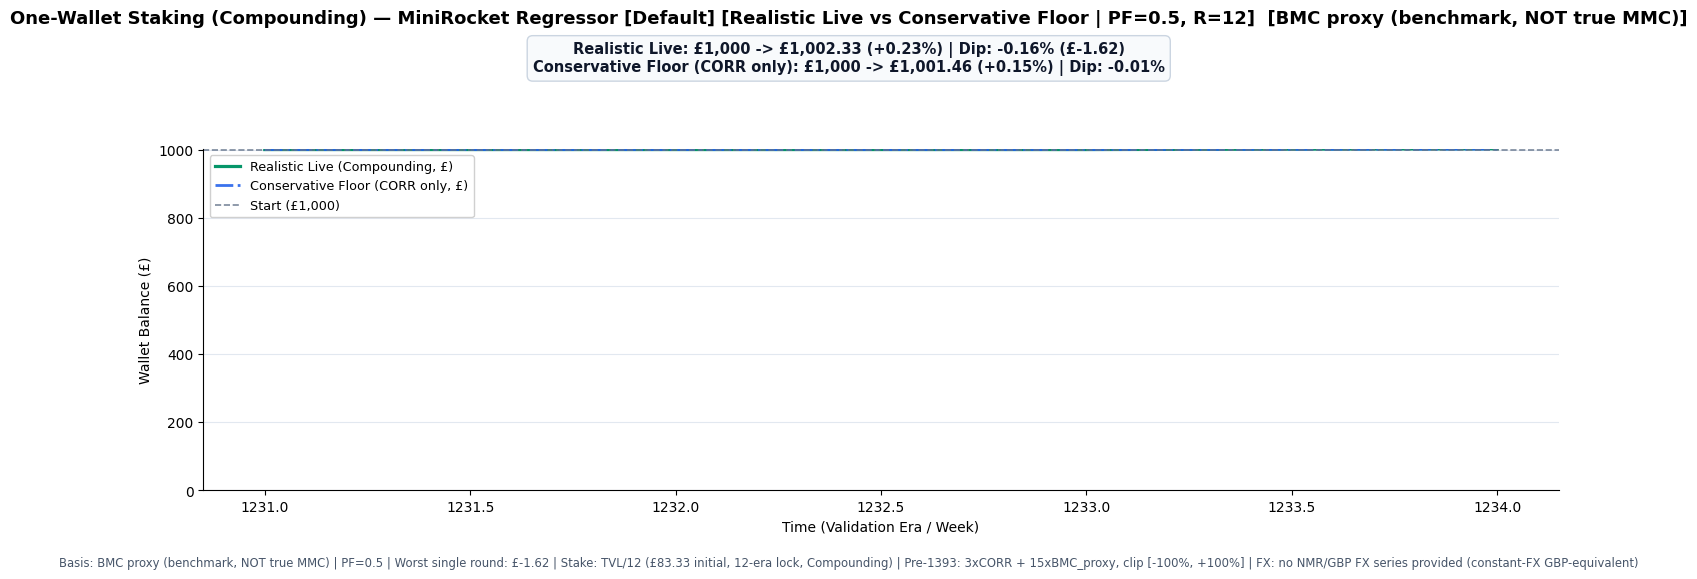

MiniRocket Regressor [Default] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,002.33 (+0.23%, Dip -0.16%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,001.46 (+0.15%, Dip -0.01%) | Basis: BMC proxy (benchmark, NOT true MMC)


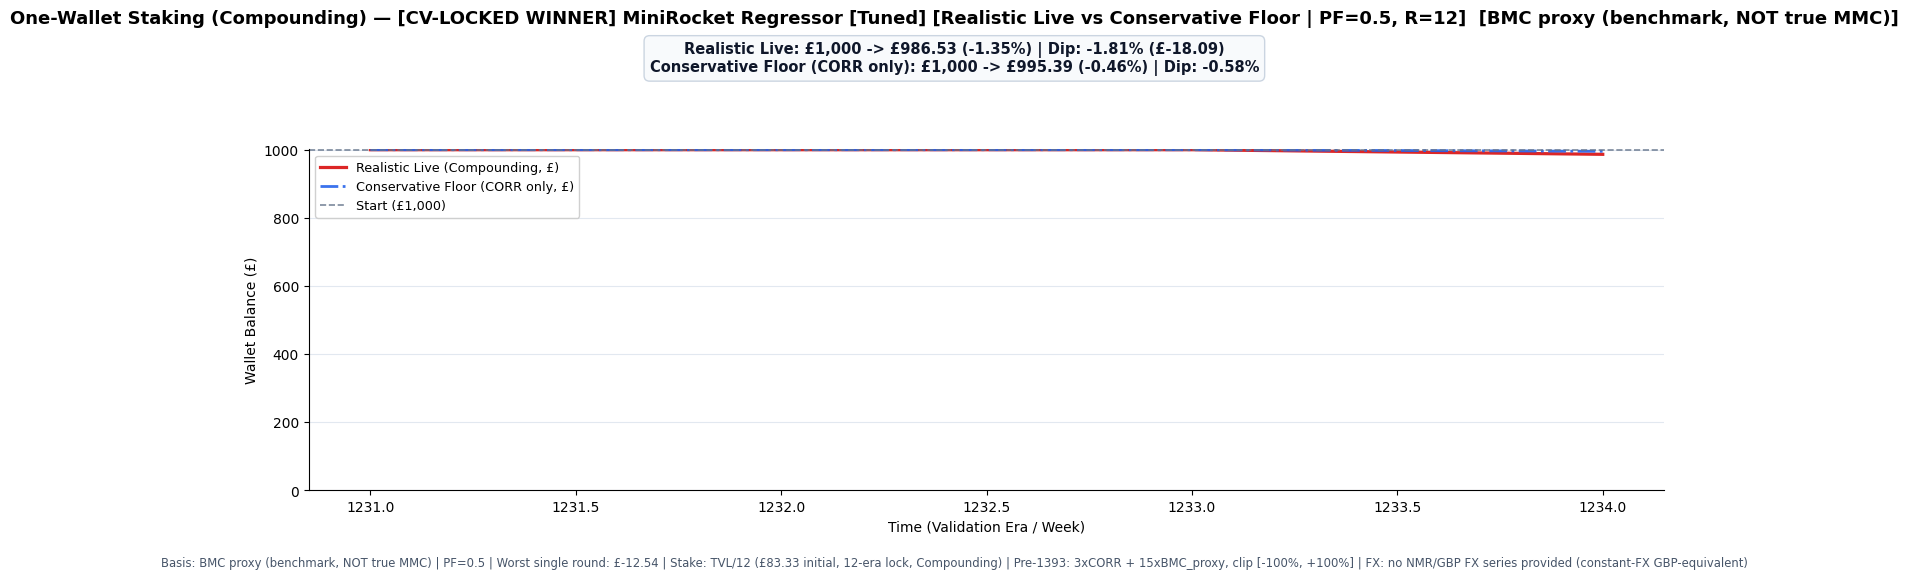

[CV-LOCKED WINNER] MiniRocket Regressor [Tuned] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £986.53 (-1.35%, Dip -1.81%) | Conservative Floor (CORR only, PF=0.5, R=12): £995.39 (-0.46%, Dip -0.58%) | Basis: BMC proxy (benchmark, NOT true MMC)


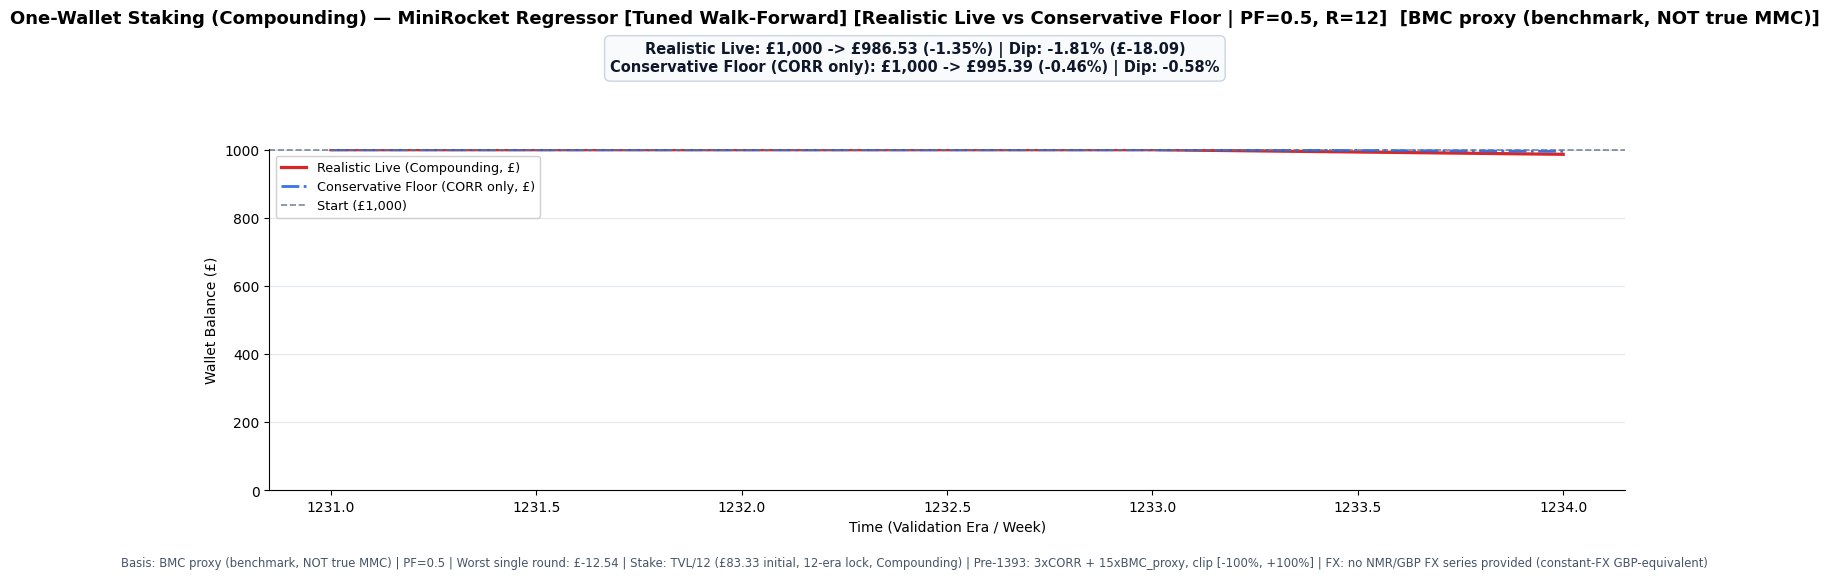

MiniRocket Regressor [Tuned Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £986.53 (-1.35%, Dip -1.81%) | Conservative Floor (CORR only, PF=0.5, R=12): £995.39 (-0.46%, Dip -0.58%) | Basis: BMC proxy (benchmark, NOT true MMC)
Dual-Scenario Realistic Live Staking Table (Conservative Floor vs. Realistic Live):


,variant,conservative_end_gbp,conservative_return_pct,conservative_worst_dip_pct,conservative_mc_p_profit_pct,realistic_live_end_gbp,realistic_live_return_pct,realistic_live_worst_dip_pct,realistic_live_mc_p_profit_pct,realistic_live_mc_median_gbp,payout_factor,bmc_haircut,concurrent_rounds
0,MiniRocket Regressor [Default],1001.46,0.15,-0.01,100.0,1002.33,0.23,-0.16,100.0,1002.33,0.5,0.5,12
1,MiniRocket Regressor [Tuned],995.39,-0.46,-0.58,0.0,986.53,-1.35,-1.81,0.0,986.53,0.5,0.5,12
2,MiniRocket Regressor [Tuned Walk-Forward],995.39,-0.46,-0.58,0.0,986.53,-1.35,-1.81,0.0,986.53,0.5,0.5,12


0

In [17]:
val_mmc_df = val_diag_meta.assign(**{TARGET_COL: y_validation.to_numpy(dtype=np.float32)})
staking_basis_label = v6_contrib_info['basis_label']
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
print(f"Active Staking Basis: {staking_basis_label}")
print(f"  -> Reason: {v6_contrib_info['reason']}")

stake_pnl_by_variant = {}
variant_era_mmc_by_variant = {}
live_scenarios_by_variant = {}
staking_summary_rows = []
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    variant_era_corrs = model_results[variant_name]['validation_era_corrs']
    variant_era_contrib = compute_per_era_mmc(
        val_mmc_df,
        model_results[variant_name]['validation_preds'],
        meta_model_path=v6_contrib_info['meta_model_path'],
        benchmark_path=v6_contrib_info['benchmark_path'],
        is_benchmark_proxy=staking_is_proxy,
        era_col=ERA_COL,
        target_col=TARGET_COL,
    )
    variant_era_mmc_by_variant[variant_name] = variant_era_contrib

    live_scenarios_by_variant[variant_name] = simulate_live_staking_scenarios(
        variant_era_corrs,
        per_era_mmc=variant_era_contrib,
        mmc_is_proxy=staking_is_proxy,
        total_capital=1000.0,
        settlement_rounds=12,
        weekly_concurrent_rounds=12,
        conservative_payout_factor=0.5,
        live_payout_factor=0.5,
        bmc_proxy_haircut=0.5,
        n_sims=500,
        block_size=12,
        random_state=random_state,
        title=variant_name,
        era_dates=val_era_dates,
    )

    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    pnl_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_stake_pnl_dashboard.png'
        if save_plots
        else None
    )
    haircutted_contrib = (
        pd.Series(variant_era_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if variant_era_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    stake_pnl_by_variant[variant_name] = plot_stake_pnl_dashboard(
        variant_era_corrs,
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        conservative_pnl=live_scenarios_by_variant[variant_name]['conservative_floor']['pnl'],
        title=f'{title_label} [Realistic Live vs Conservative Floor | PF=0.5, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        era_dates=val_era_dates,
        save_path=pnl_save_path,
    )

    v_pnl = stake_pnl_by_variant[variant_name]
    c_pnl = live_scenarios_by_variant[variant_name]['conservative_floor']['pnl']
    mean_contrib = float(variant_era_contrib.mean()) if variant_era_contrib is not None and len(variant_era_contrib) > 0 else np.nan
    contrib_col_name = 'validation_bmc_proxy' if staking_is_proxy else 'validation_true_mmc'
    staking_summary_rows.append({
        'variant': variant_name,
        'staking_basis': v_pnl['score_basis'],
        'staking_mode': 'One-Wallet (Compounding, PF=0.5, R=12)',
        'validation_corr': round(float(variant_era_corrs.mean()), 4),
        contrib_col_name: round(mean_contrib, 4) if np.isfinite(mean_contrib) else np.nan,
        'start_capital': round(float(v_pnl['start_capital']), 2),
        'end_capital': round(float(v_pnl['end_capital']), 2),
        'total_return_pct': round(float(v_pnl['total_return_pct']), 2),
        'worst_dip_pct': round(float(v_pnl['money_drawdown_pct']), 2),
        'worst_dip_gbp': round(float(v_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(v_pnl['worst_round_gbp']), 2),
    })
    print(
        f"{title_label} | Realistic Live (PF=0.5, 0.5x BMC, R=12): £{v_pnl['end_capital']:,.2f} ({v_pnl['total_return_pct']:+.2f}%, Dip {v_pnl['money_drawdown_pct']:.2f}%) | "
        f"Conservative Floor (CORR only, PF=0.5, R=12): £{c_pnl['end_capital']:,.2f} ({c_pnl['total_return_pct']:+.2f}%, Dip {c_pnl['money_drawdown_pct']:.2f}%) | "
        f"Basis: {v_pnl['score_basis']}"
    )

staking_comparison_df = pd.DataFrame(staking_summary_rows)
live_staking_scenarios_df = build_live_staking_scenarios_df(live_scenarios_by_variant)
comparison_df['staking_basis'] = comparison_df['variant'].map(
    staking_comparison_df.set_index('variant')['staking_basis']
)
if staking_is_proxy:
    comparison_df['validation_bmc_proxy'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_bmc_proxy']
    )
elif v6_contrib_info['basis_kind'] == 'true_mmc':
    comparison_df['validation_true_mmc'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_true_mmc']
    )
display_compact_dataframe(
    live_staking_scenarios_df,
    title='Dual-Scenario Realistic Live Staking Table (Conservative Floor vs. Realistic Live):',
)
best_stake_pnl = stake_pnl_by_variant[best_variant_name]
del val_mmc_df, val_diag_meta
gc.collect()
del stake_pnl_by_variant, staking_comparison_df, live_staking_scenarios_df, best_stake_pnl
gc.collect()

### 2B. Monte Carlo Block-Bootstrap Risk Analysis (£)

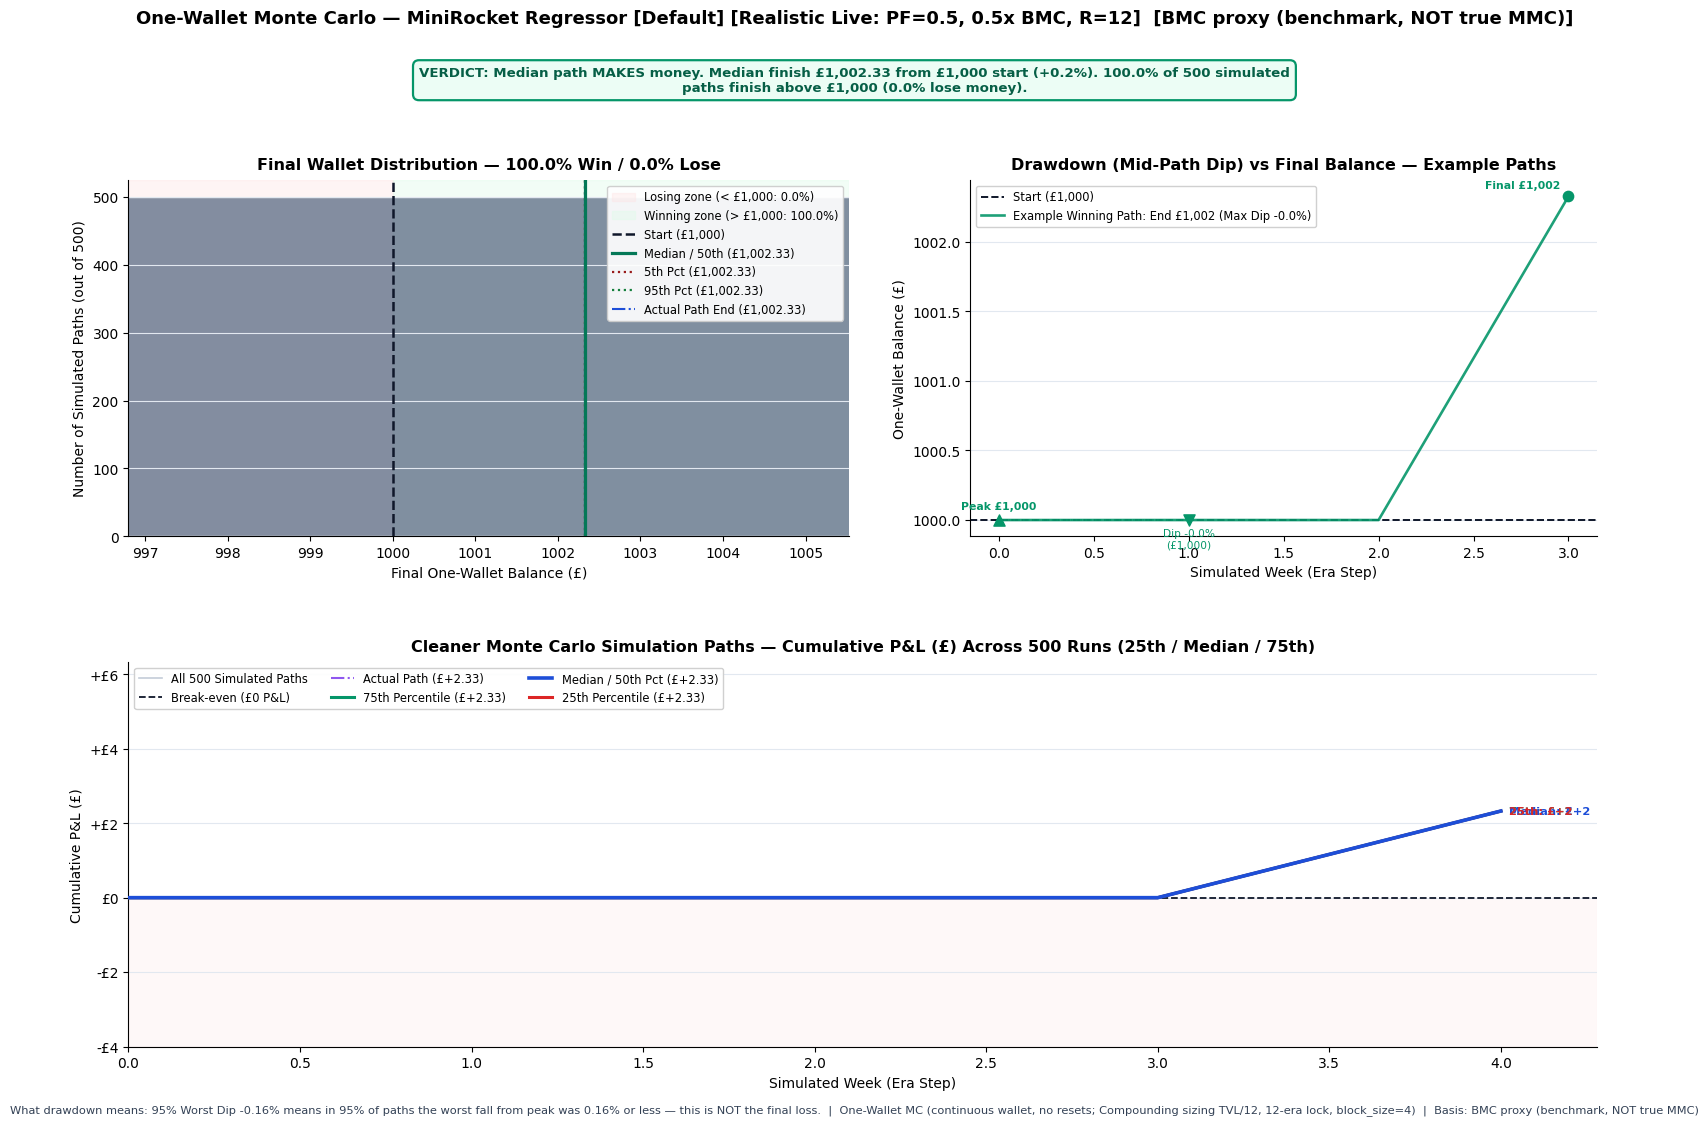

MiniRocket Regressor [Default] — VERDICT: Median path MAKES money. Median finish £1,002.33 from £1,000 start (+0.2%). 100.0% of 500 simulated paths finish above £1,000 (0.0% lose money).

How to read Drawdown vs Final Balance (Plain English):
  • Drawdown is the biggest peak-to-trough dip DURING the journey — NOT your final profit or loss.
  • Worked example (Winning path with a drawdown): Start £1,000 -> rises to £1,200 peak -> dips to £1,100 (-8.3% drawdown from peak) -> recovers to £1,300. You still finish +£300 ABOVE £1,000 despite the dip.
  • Worked example (Losing path with a small drawdown): Start £1,000 -> drifts down to £955 (-4.5% dip) and ends at £984.81. A small drawdown still finishes BELOW £1,000 if it never recovers.
  • Median (50th) vs 95th percentile are DIFFERENT paths: Median = typical path; 95th = lucky top 5% of paths.
  • One-Wallet MC: Simulates ONE continuous wallet from start to finish over the full validation period with no resets.
  • Within-Window MC: Simu

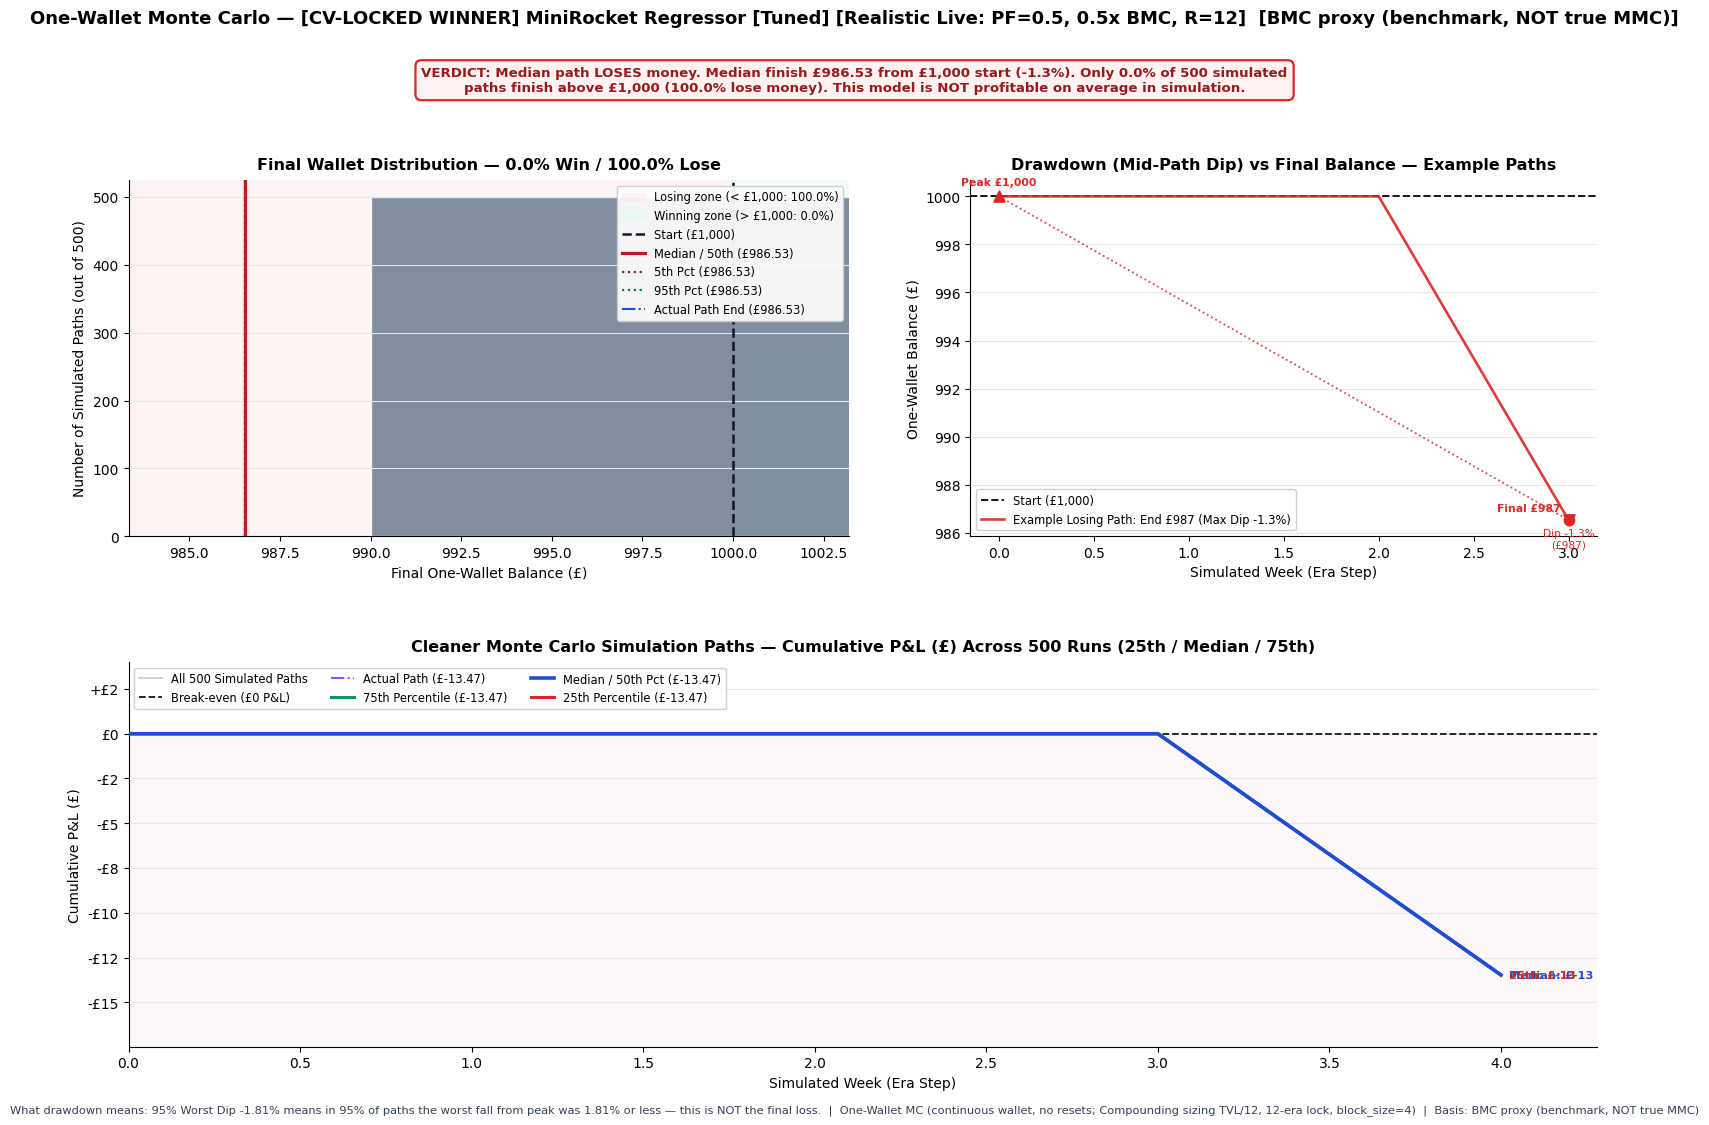

[CV-LOCKED WINNER] MiniRocket Regressor [Tuned] — VERDICT: Median path LOSES money. Median finish £986.53 from £1,000 start (-1.3%). Only 0.0% of 500 simulated paths finish above £1,000 (100.0% lose money). This model is NOT profitable on average in simulation.

[CV-LOCKED WINNER] MiniRocket Regressor [Tuned] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 0.0% (100.0% lose) | Median (50th): £986.53 (-1.3%) | 5th Pct: £986.53 | 95th Pct: £986.53 | 95% Worst Dip: -1.81% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -1.81% means in 95% of paths the worst fall from peak was 1.81% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=0.0% | Median=£995.39 | 95% Worst Dip=-0.58%


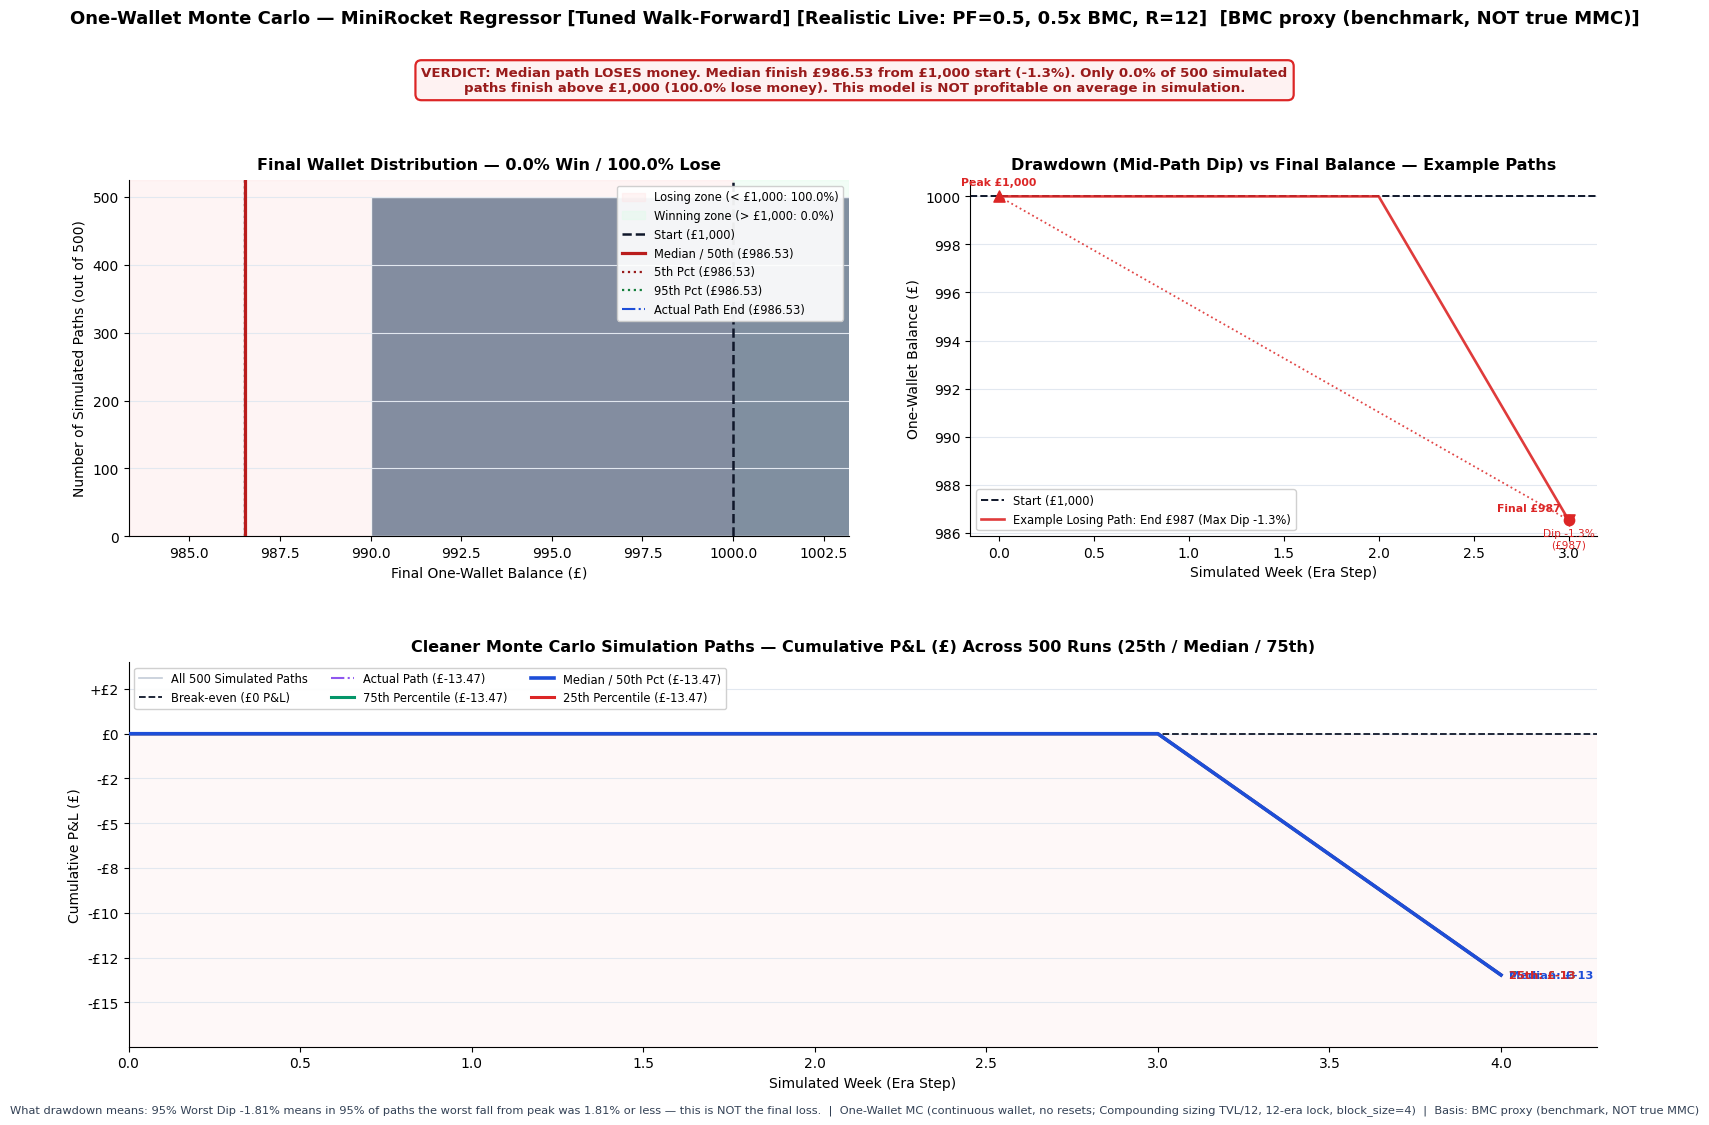

MiniRocket Regressor [Tuned Walk-Forward] — VERDICT: Median path LOSES money. Median finish £986.53 from £1,000 start (-1.3%). Only 0.0% of 500 simulated paths finish above £1,000 (100.0% lose money). This model is NOT profitable on average in simulation.

MiniRocket Regressor [Tuned Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 0.0% (100.0% lose) | Median (50th): £986.53 (-1.3%) | 5th Pct: £986.53 | 95th Pct: £986.53 | 95% Worst Dip: -1.81% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -1.81% means in 95% of paths the worst fall from peak was 1.81% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=0.0% | Median=£995.39 | 95% Worst Dip=-0.58%


0

In [18]:
mc_risk_by_variant = {}
explainer_printed = False
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    mc_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_monte_carlo_pnl.png'
        if save_plots
        else None
    )
    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    raw_contrib = variant_era_mmc_by_variant.get(variant_name)
    haircutted_contrib = (
        pd.Series(raw_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if raw_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    v_mc = plot_stake_pnl_monte_carlo(
        model_results[variant_name]['validation_era_corrs'],
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        title=f'{title_label} [Realistic Live: PF=0.5, 0.5x BMC, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        n_sims=500,
        block_size=12,
        random_state=random_state,
        era_dates=val_era_dates,
        save_path=mc_save_path,
        retain_paths=False,
    )
    mc_risk_by_variant[variant_name] = v_mc
    c_mc = live_scenarios_by_variant[variant_name]['conservative_floor']['mc']
    print('=' * 100)
    print(f"{title_label} — {v_mc['mc_verdict_text']}")
    if not explainer_printed:
        print()
        print(v_mc['mc_explainer_text'])
        explainer_printed = True
    print()
    print(v_mc['mc_summary_line'])
    print(f"  -> {v_mc['mc_drawdown_explanation_line']}")
    print(
        f"  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)={c_mc['mc_prob_profit_pct']:.1f}% | "
        f"Median=£{c_mc['mc_median_final_stake']:,.2f} | 95% Worst Dip={c_mc['mc_p95_money_drawdown_pct']:.2f}%"
    )
    print('=' * 100)
gc.collect()
del mc_risk_by_variant, v6_contrib_info, variant_era_mmc_by_variant, live_scenarios_by_variant
gc.collect()

### 2C–2D. Cumulative (2C) & Rolling 20-Era (2D) Validation CORR

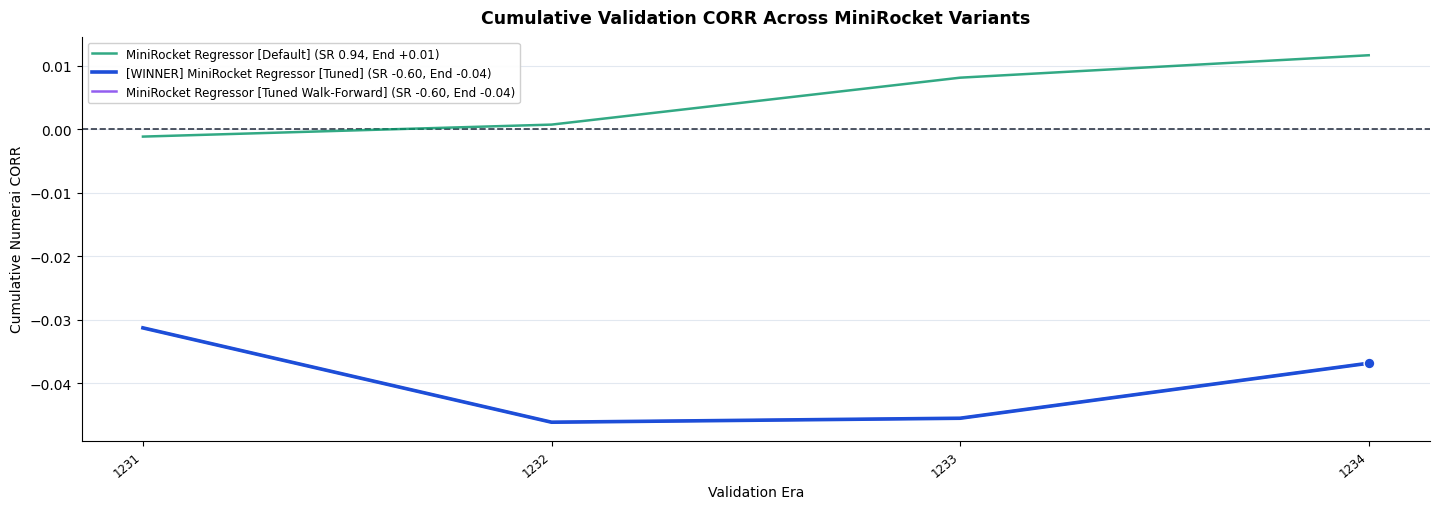

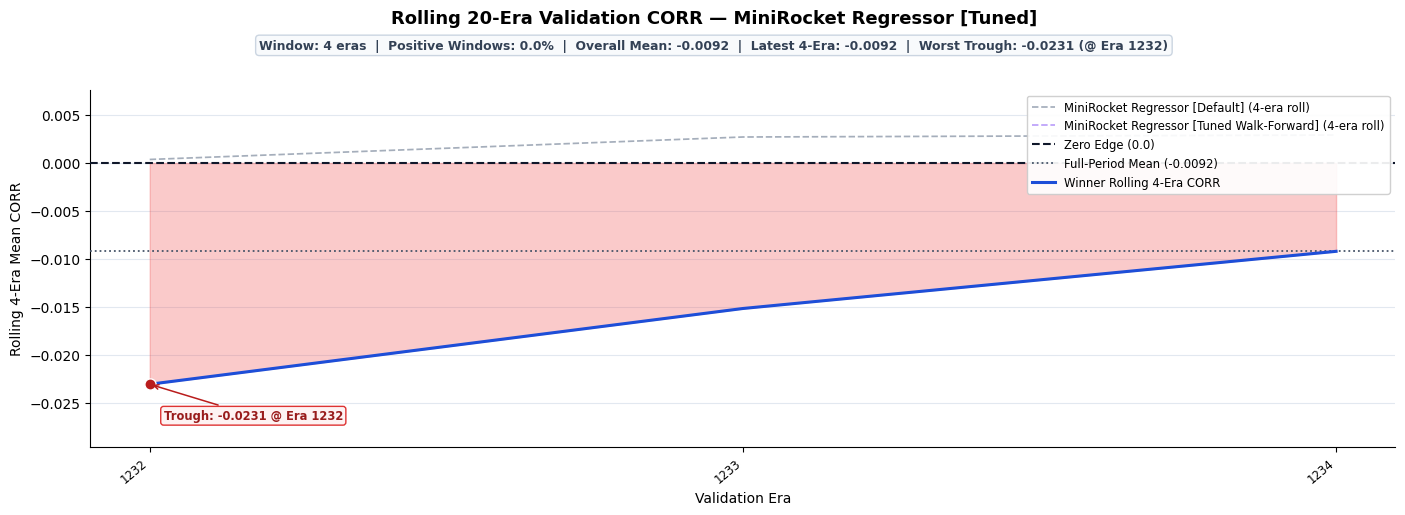

3942

In [19]:
cum_corr_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_cumulative_validation_corr.png'
    if save_plots
    else None
)
cumulative_corr_df = plot_cumulative_validation_corr(
    model_results,
    best_variant_name=best_variant_name,
    title='Cumulative Validation CORR Across MiniRocket Variants',
    save_path=cum_corr_save_path,
)

secondary_era_corrs = {
    v_name: v_res['validation_era_corrs']
    for v_name, v_res in model_results.items()
    if v_name != best_variant_name
}
rolling_corr_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_rolling_20era_validation_corr.png'
    if save_plots
    else None
)
rolling_20era_corr = plot_rolling_validation_corr(
    best_validation_era_corrs,
    window=20,
    comparison_corrs=secondary_era_corrs,
    title=f'Rolling 20-Era Validation CORR — {best_variant_name}',
    save_path=rolling_corr_save_path,
)
del cumulative_corr_df, secondary_era_corrs, rolling_20era_corr
gc.collect()

## 3. Model Diagnostics & Residual Visuals (3A–3E)
Compact feature-neutral & error diagnostics table, peak-annotated error-direction envelope, side-by-side Top-2 variants Residuals vs. Actual plot, and model-specific interpretability.

### 3A. Model Diagnostics Table

In [20]:
diagnostics_table_df = build_diagnostics_summary_table(
    comparison_df,
    best_variant_name=best_variant_name,
)
display_compact_dataframe(
    diagnostics_table_df,
    title='3A. Model Diagnostics Table (Feature Exposure, FNC, MAE, Forecast Bias & Hit Rate):',
)
del diagnostics_table_df
gc.collect()

3A. Model Diagnostics Table (Feature Exposure, FNC, MAE, Forecast Bias & Hit Rate):


,variant,feature_exposure,validation_fnc,validation_fnc_sharpe,validation_mae,forecast_bias,directional_hit_rate
0,[WINNER] MiniRocket Regressor [Tuned],0.0694,NaN,NaN,0.8052,0.000,0.5022
1,MiniRocket Regressor [Default],0.0727,NaN,NaN,0.1556,0.005,0.4986
2,MiniRocket Regressor [Tuned Walk-Forward],0.0694,NaN,NaN,0.8052,0.000,0.5022


0

### 3B. Error-Direction Envelope Analysis

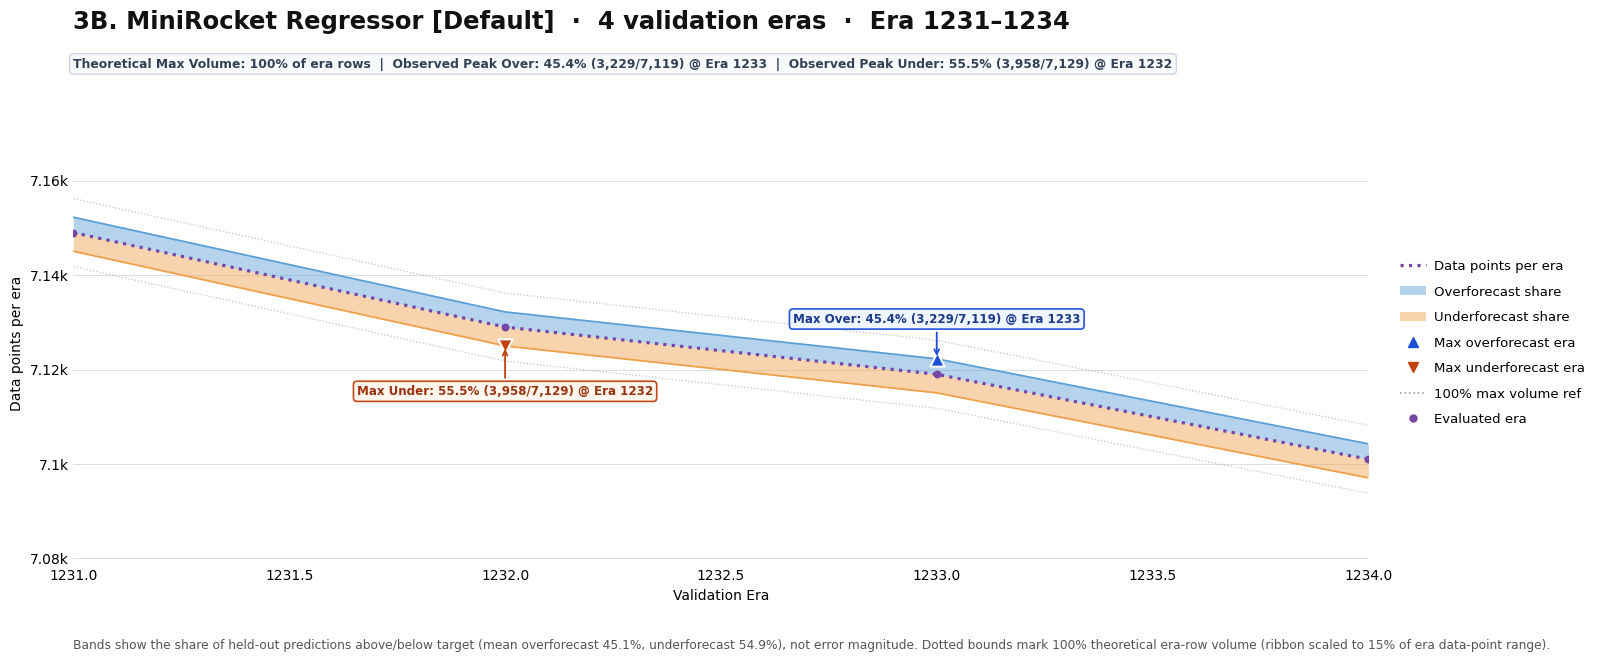

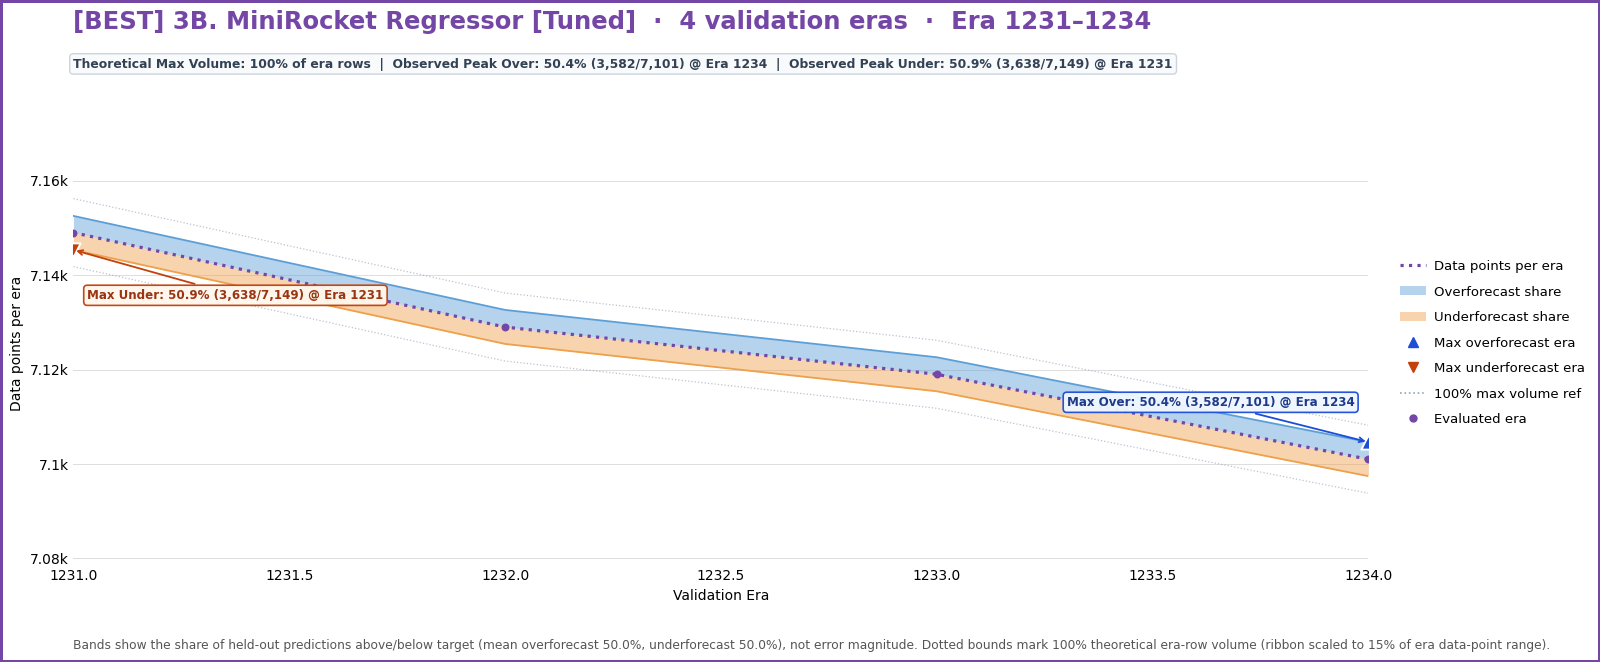

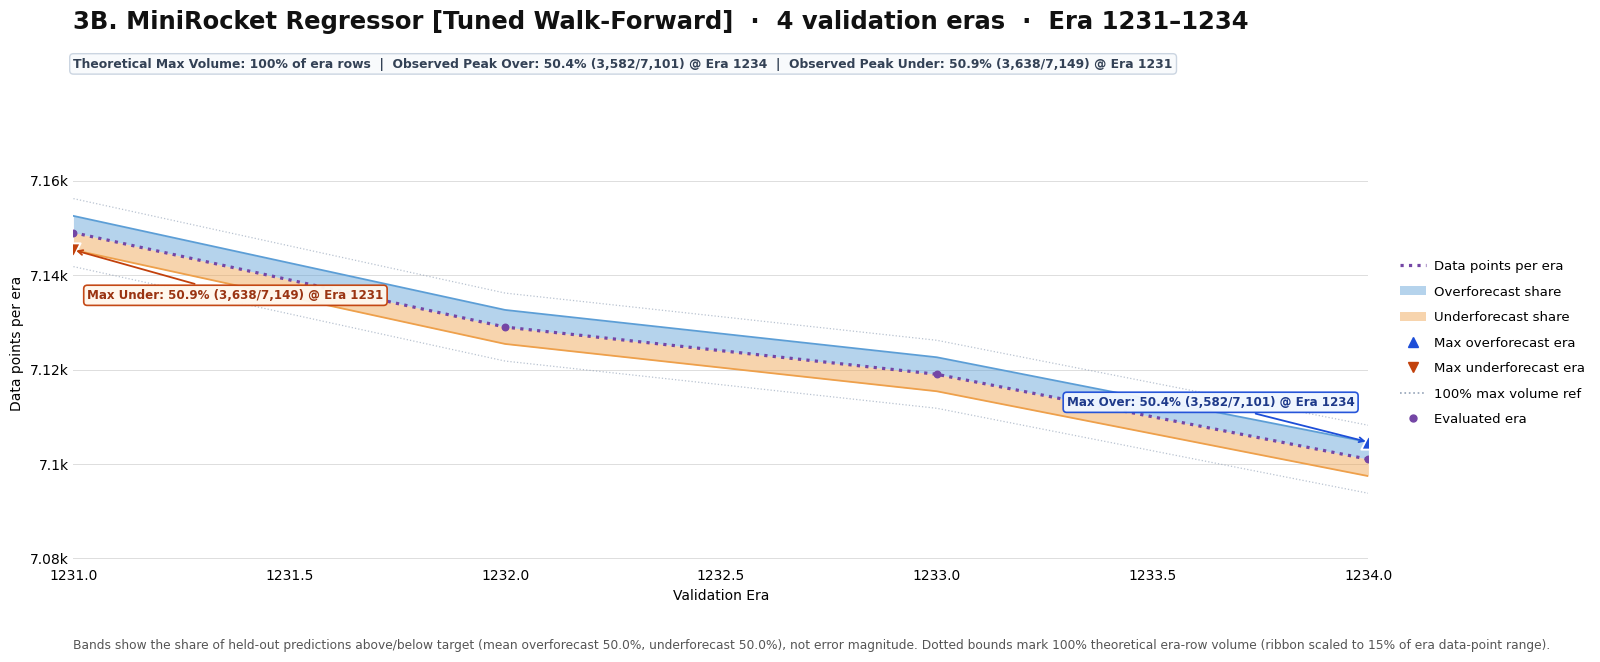

3B. Best Model Envelope Summary (MiniRocket Regressor [Tuned]):


,data_points,under_share,over_share,under_count,over_count,mae,mean_residual,is_interpolated
era,,,,,,,,
1231,7149,0.508882,0.491118,3638,3511,0.803310,-0.000004,False
1232,7129,0.496423,0.503577,3539,3590,0.806307,-0.000004,False
1233,7119,0.499368,0.500632,3555,3564,0.805515,-0.000004,False
1234,7101,0.495564,0.504436,3519,3582,0.805774,-0.000004,False


4523

In [21]:
envelope_dfs = {}
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    envelope_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_error_envelope.png'
        if save_plots
        else None
    )
    envelope_dfs[variant_name] = plot_era_error_envelope(
        y_validation,
        model_results[variant_name]['validation_preds'],
        validation_eras,
        title=f'3B. {variant_name}',
        band_size=0.15,
        is_best=is_best_variant,
        save_path=envelope_save_path,
    )

envelope_df = envelope_dfs[best_variant_name]
display_compact_dataframe(
    envelope_df.head(10),
    title=f'3B. Best Model Envelope Summary ({best_variant_name}):',
)
del envelope_dfs
gc.collect()

### 3C. Top-2 Variants Residual Diagnostics

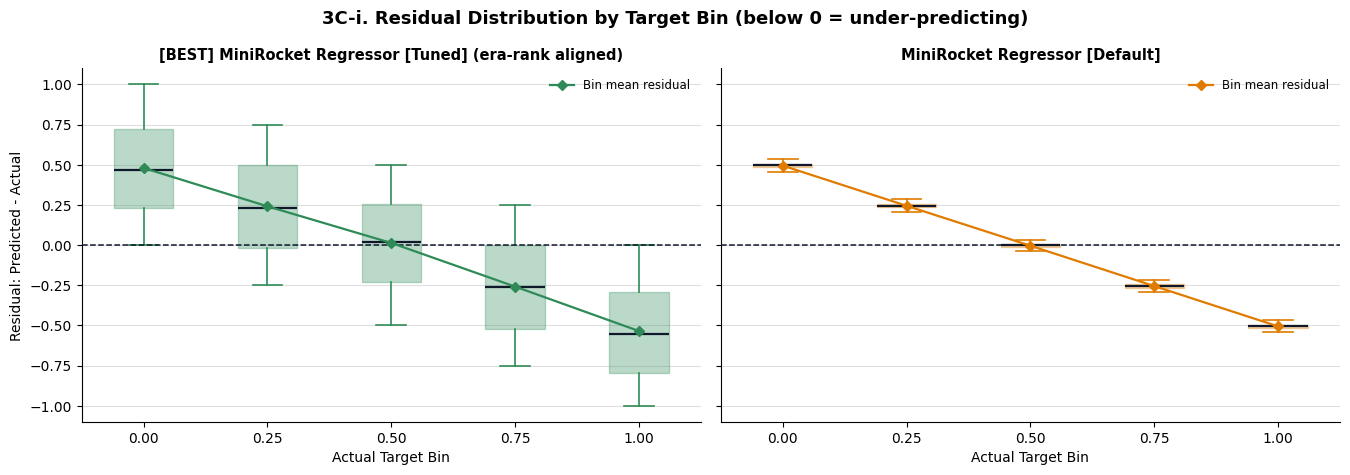

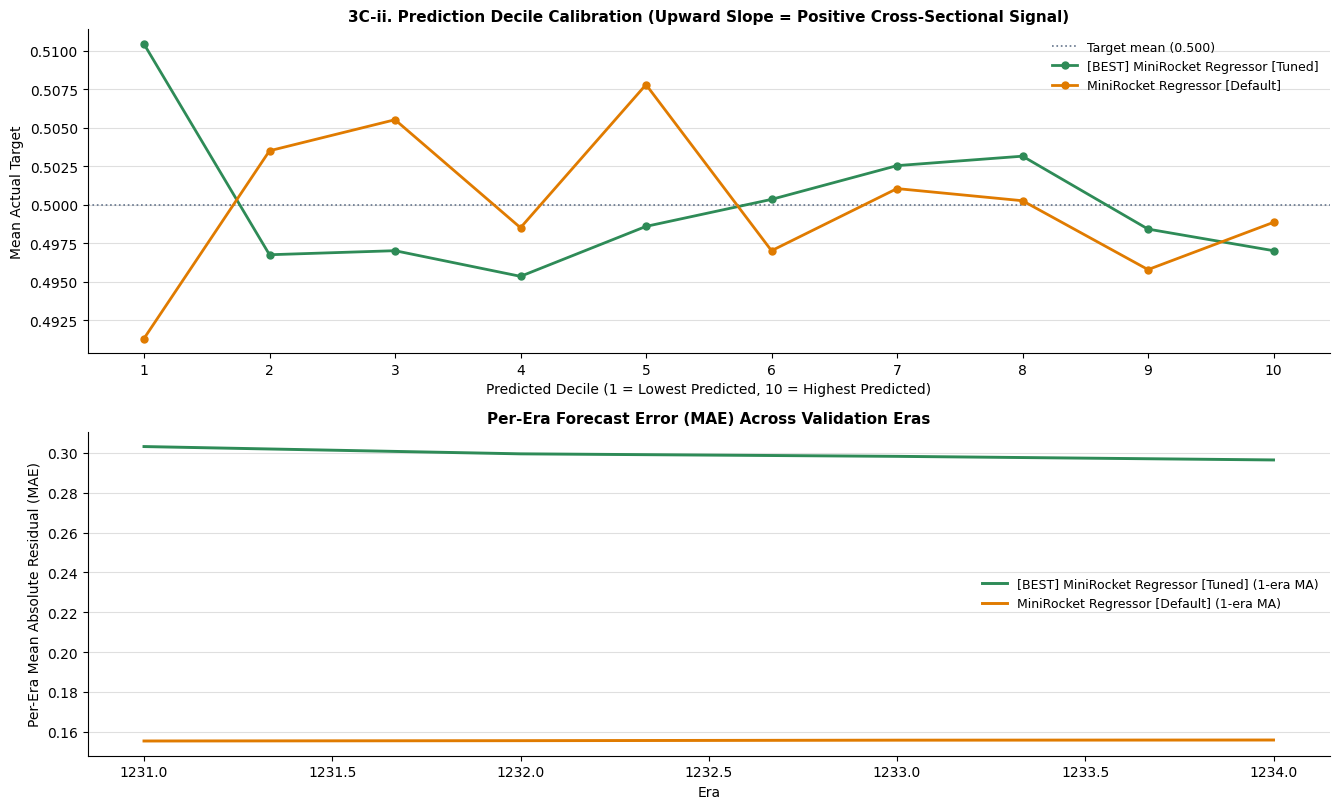

3C. Top-2 Variants Residual Diagnostics Summary:


,variant,n_valid,mean_residual,mae,rmse,under_predict_pct,over_predict_pct
0,[BEST] MiniRocket Regressor [Tuned],28498,0.000105,0.2994,0.3661,49.22,50.77
1,MiniRocket Regressor [Default],28498,-0.004966,0.1556,0.2241,54.94,45.06


0

In [22]:
resid_diag_save_prefix = (
    results_dir / f'{timestamp}_{experiment_name}_residual_diagnostics'
    if save_plots
    else None
)
residual_diag_summary_df = plot_residual_diagnostics(
    y_validation,
    model_results,
    validation_eras,
    best_variant_name=best_variant_name,
    variant_order=comparison_df['variant'].tolist(),
    max_models=2,
    random_state=random_state,
    save_prefix=resid_diag_save_prefix,
)
display_compact_dataframe(
    residual_diag_summary_df,
    title='3C. Top-2 Variants Residual Diagnostics Summary:',
)

numereval_summary_df = run_numereval_diagnostics(
    y_validation,
    model_results[best_variant_name]['validation_preds'],
    validation_eras,
    variant_name=best_variant_name,
    plot=False,
    verbose=False,
)
strip_validation_predictions(model_results)
del y_validation, validation_eras
gc.collect()

### 3D–3E. Model Interpretability (3D) & Top CV Candidates (3E)

MiniRocket Fitted Summary | backend=numpy | input_mode=ticker_sequence | channels=16 | seq_len=12 | rocket_features=840 | head=ridge_cv (alpha=1e+05)
Top 20 MiniRocket PPV Kernels by |Weight|:


,rocket_feature,kernel_id,dilation,bias,coef,abs_coef,ppv_mean,ppv_std
0,k76_d1_f760,76,1,-4.000000,0.000487,0.000487,0.882793,0.100295
1,k36_d1_f367,36,1,4.000000,-0.000466,0.000466,0.162894,0.140725
2,k36_d1_f368,36,1,4.000000,-0.000466,0.000466,0.162894,0.140725
3,k36_d1_f369,36,1,4.000000,-0.000466,0.000466,0.162894,0.140725
4,k76_d1_f769,76,1,6.000000,-0.000465,0.000465,0.100676,0.097329
5,k62_d1_f622,62,1,-4.000000,-0.000449,0.000449,0.831946,0.139481
6,k56_d1_f565,56,1,2.000000,-0.000418,0.000418,0.422475,0.035216
7,k56_d1_f564,56,1,2.000000,-0.000418,0.000418,0.422475,0.035216
8,k60_d1_f600,60,1,-14.000000,-0.000414,0.000414,0.930048,0.082278
9,k28_d1_f287,28,1,14.000000,0.000413,0.000413,0.240081,0.073700


Top 20 Input Channels by Aggregated MiniRocket Kernel Weight:


,feature,kernel_weight_sum,train_corr
0,feature_constitution_172,0.009108,0.014612
1,feature_constitution_322,0.008009,-0.013805
2,feature_charisma_7,0.007889,0.021831
3,feature_dexterity_14,0.006275,-0.021638
4,feature_charisma_147,0.005959,0.019554
5,feature_constitution_121,0.005805,-0.016133
6,feature_constitution_318,0.005726,-0.017862
7,feature_constitution_217,0.005561,-0.013270
8,feature_constitution_277,0.005118,0.014643
9,feature_constitution_308,0.005065,0.018052


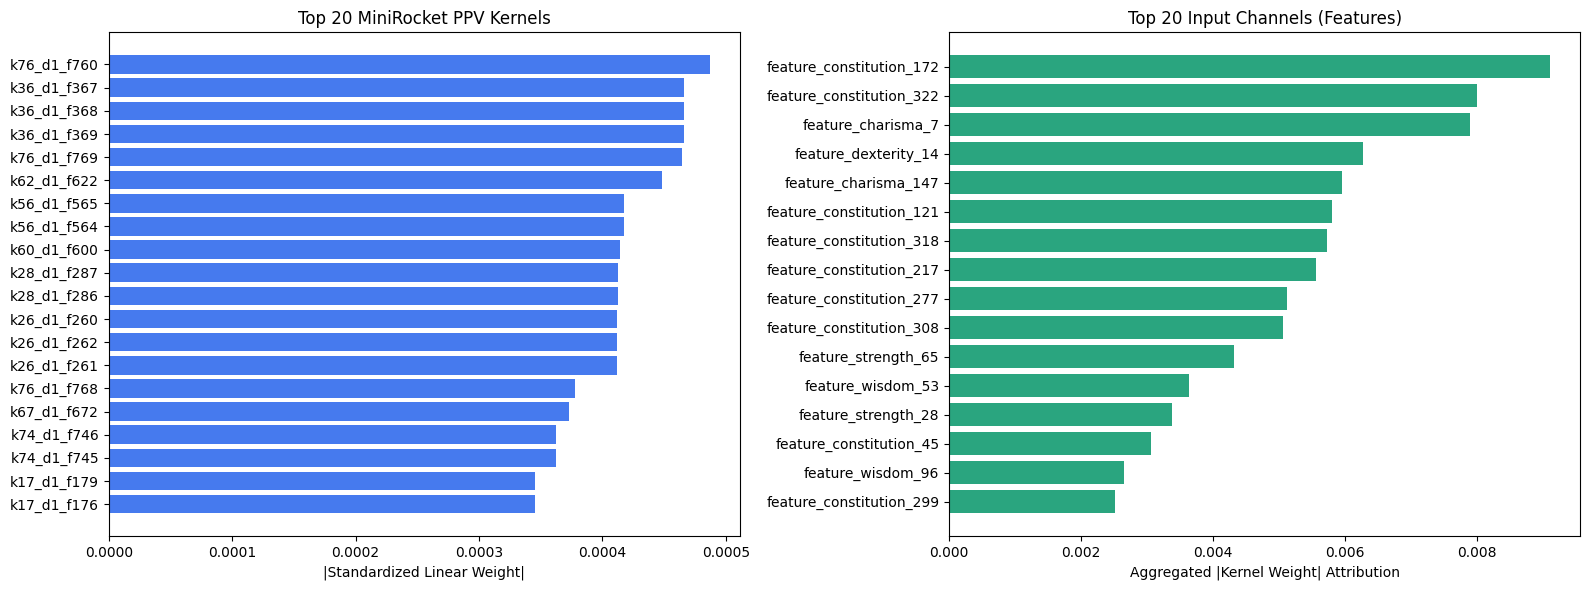

3D-iii. MiniRocket Feature Group Distribution by Kernel Weight (Lift = Importance % / Feature %):


,feature_group,n_features,feature_share_pct,importance_share_pct,importance_lift
0,constitution,9,56.25,59.42,1.06
1,charisma,2,12.50,16.47,1.32
2,strength,2,12.50,9.15,0.73
3,wisdom,2,12.50,7.49,0.60
4,dexterity,1,6.25,7.46,1.19


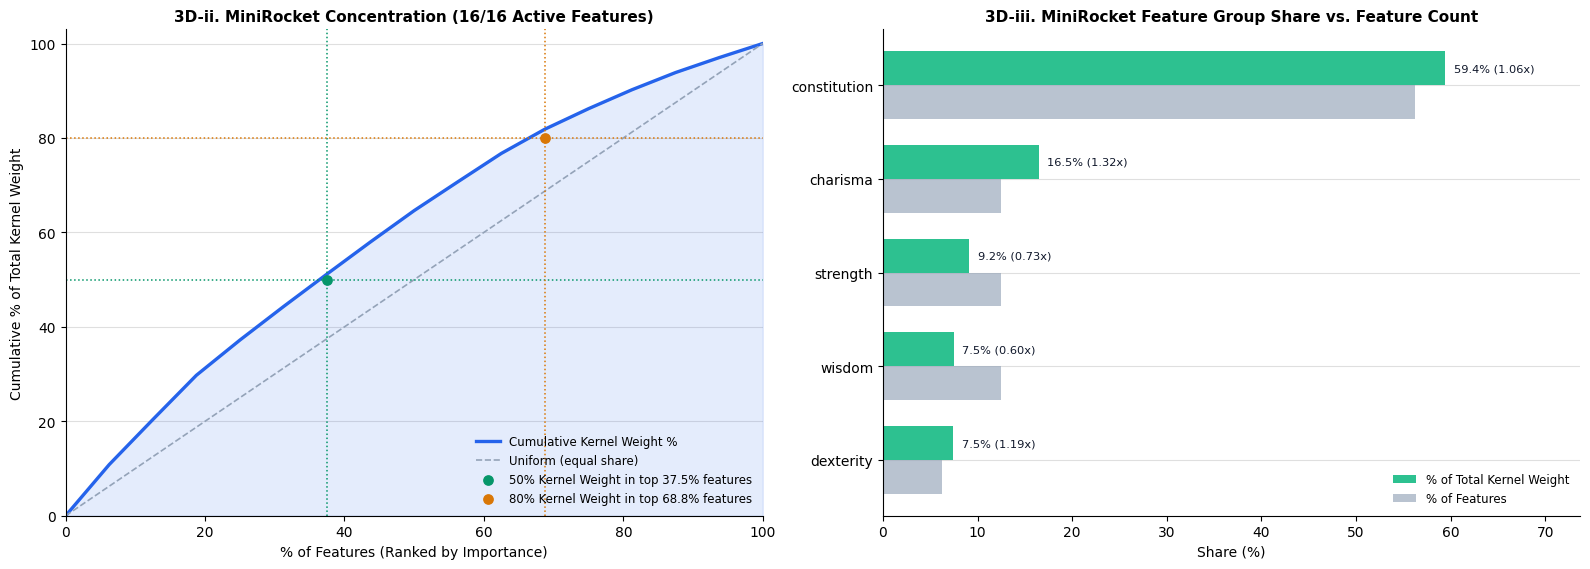

17073

In [23]:
display_minirocket_interpretability(
    minirocket_interpretability,
    results_dir=results_dir,
    timestamp=timestamp,
    experiment_name=experiment_name,
    save_results=save_plots,
)
del minirocket_interpretability
gc.collect()

In [24]:
display_top_cv_candidates(cv_analysis_artifacts)

Top CV candidates for MiniRocket Regressor:


,candidate_id,rank_test_score,mean_test_score,score_version,end_capital,total_profit,total_return_pct,money_drawdown_pct,mean_directional_accuracy_pct,mean_accurate_pct,mean_numerai_corr,mean_sharpe,mean_positive_era_pct,mean_era_consistency_pct,mean_corr_drawdown,mean_mae,mean_fit_time,std_fit_time,mean_score_time,std_score_time,split0_test_score,std_test_score,mean_test_score_pct,mean_era_corr_std,mean_underforecast_pct,mean_extreme_underforecast_pct,mean_overforecast_pct,mean_extreme_overforecast_pct,mean_spearman,mean_forecast_bias,start_capital,max_drawdown_gbp,worst_round_gbp,abs_corr,alpha,bias_correction,correlation_method,era_weighting,extractor__abs_corr,extractor__basic_group_stats,extractor__correlation_method,extractor__era_dispersion_features,extractor__era_lag_scales,extractor__feature_selection_percentile,extractor__fourier_order,extractor__fourier_period_eras,extractor__include_lag_diff,extractor__include_rolling_era,extractor__missing_fill_value,extractor__pca_n_components,extractor__quantize_scope,extractor__quantize_strategy,extractor__rolling_era_windows,extractor__sequence_top_n,extractor__sparse_alpha,extractor__sparse_selector,extractor__ticker_features,extractor__ticker_lag_steps,extractor__ticker_windows,extractor__top_k,extractor__variance_threshold,extractor__year_horizon_filter,fit_sample_size,head_type,huber_epsilon,input_mode,l1_ratio,max_channels,max_dilations_per_kernel,num_kernels,pad_mode,prediction_transform,recency_decay,seq_len,standardize_features,top_k
0,0,1,-0.005102,v1_skepta,999.76,-0.24,-0.02,-0.02,49.87,1.82,-0.0051,0.0,0.0,0.0,0.0051,0.829,4.349365,0.0,1.26843,0.0,-0.005102,0.0,-0.51,0.0,0.94,48.63,0.91,47.71,-0.0001,-0.0,1000.0,-0.24,-0.24,True,1241.881628,mean_residual,pandas_mean,uniqueness,True,std,pearson,std,"[1, 2, 4, 8]",50.0,None,52,True,False,median,20,global,zscore,"[4, 8, 16]",4,0.000103,elasticnet,rolling_mean|momentum_diff,None,"[2, 6, 12]",10,0.05,"[1, 2, 3]",2048,ridge,1.300947,ticker_sequence,0.560911,16,32,2044,first,era_zscore,0.007001,9,False,None


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride12_minirocket_target_bayes/20261126_111929_numerai_v6.0_all_eras_stride12_minirocket_bayes_cv.csv


## 4. AFML Backtest Visual Story (4A–4B)
2×2 statistical credibility dashboard for the Train-CV-Locked Winner (**PSR/DSR vs. 95%**, **Observed Eras vs. MinTRL**, **Underwater / Time-Underwater Curve**, and **HHI Concentration & Regime Health**) followed by the compact AFML reference table.

### 4A. Statistical Credibility & Regime Dashboard

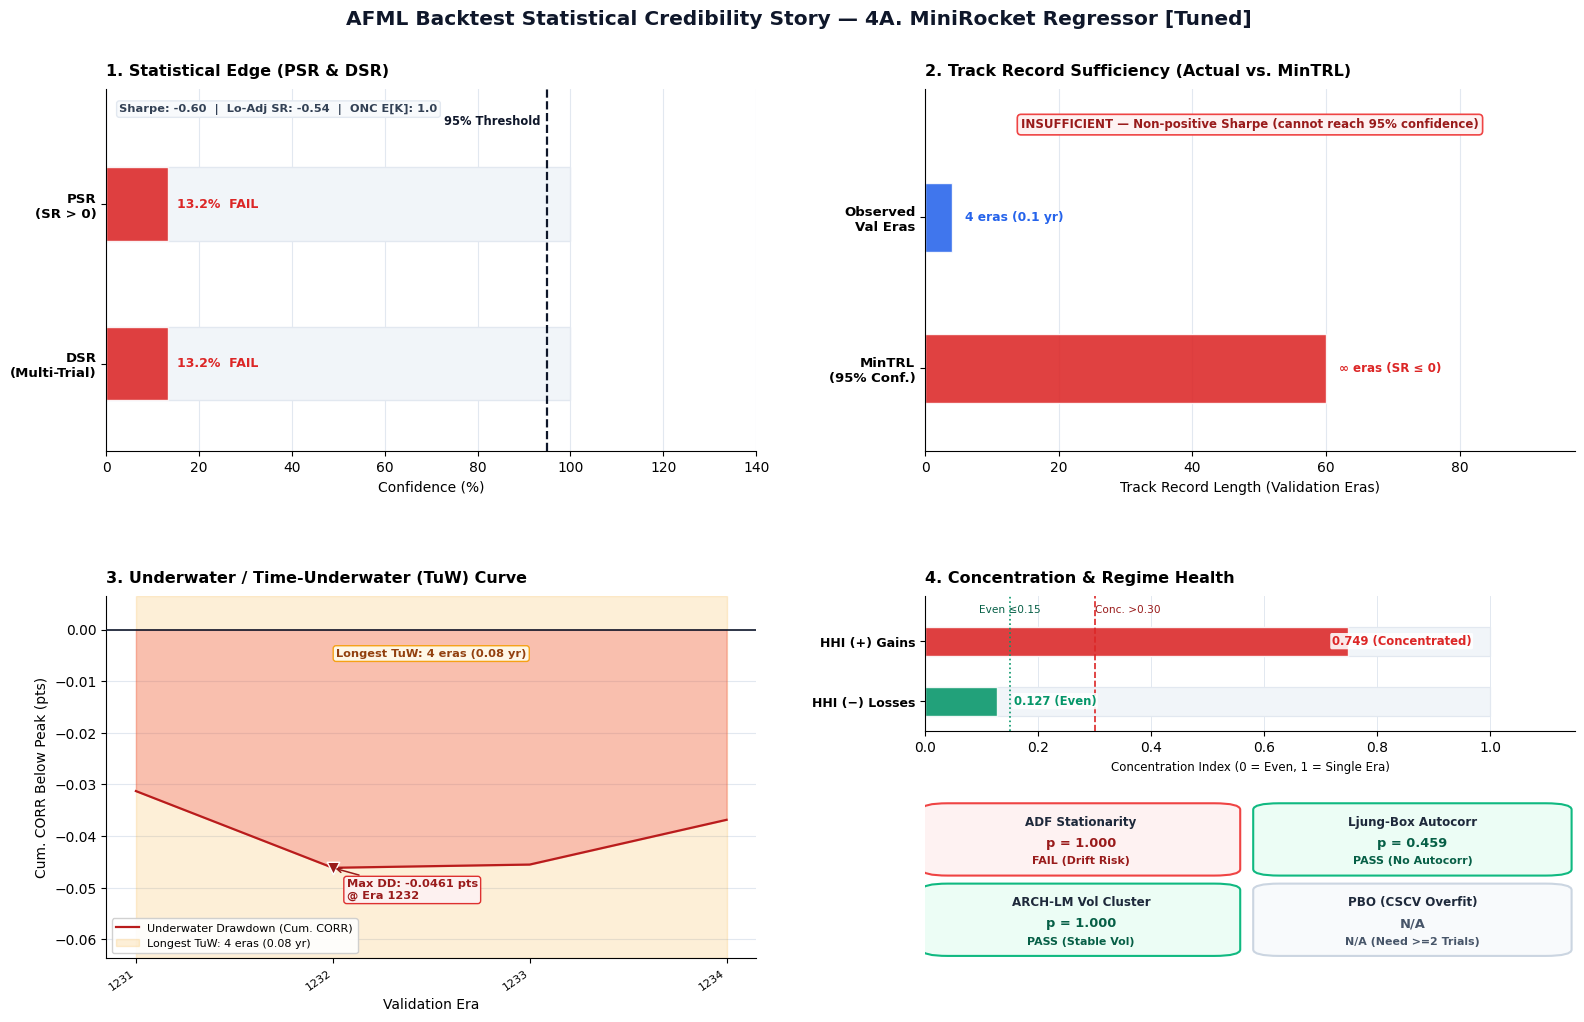

13423

In [25]:
afml_diagnostics_df = build_afml_diagnostics_df(
    model_results,
    cv_trial_stats_by_baseline=cv_analysis_artifacts['trial_stats'],
    random_state=random_state,
)

winner_afml_matches = afml_diagnostics_df.loc[afml_diagnostics_df['variant'].astype(str) == str(best_variant_name)]
winner_afml_row = (
    winner_afml_matches.reset_index(drop=True).loc[0].to_dict()
    if not winner_afml_matches.empty
    else afml_diagnostics_df.reset_index(drop=True).loc[0].to_dict()
)
afml_story_save_path = (
    results_dir / f'{timestamp}_{experiment_name}_afml_backtest_story.png'
    if save_plots
    else None
)
afml_story_summary = plot_afml_backtest_story(
    best_validation_era_corrs,
    winner_afml_row,
    regime_stats=model_results[best_variant_name],
    title=f'4A. {best_variant_name}',
    save_path=afml_story_save_path,
)
del afml_story_summary, winner_afml_matches, winner_afml_row
gc.collect()

### 4B. AFML Backtest Credibility Reference Table

In [26]:
compact_afml_df = build_compact_afml_reference_table(
    afml_diagnostics_df,
    best_variant_name=best_variant_name,
)
display_compact_dataframe(
    compact_afml_df,
    title='4B. AFML Backtest Credibility Reference Table (PSR, DSR, MinTRL, PBO, TuW & HHI):',
)
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    afml_diagnostics_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_afml_diagnostics.csv', index=False)
del compact_afml_df, afml_diagnostics_df
gc.collect()

4B. AFML Backtest Credibility Reference Table (PSR, DSR, MinTRL, PBO, TuW & HHI):


,variant,n_eras,numerai_sharpe,lo_adjusted_sharpe,psr,dsr,min_trl_years,pbo_cscv,tuw_max_years,hhi_pos,hhi_neg,strategy_fail_prob
0,[WINNER] MiniRocket Regressor [Tuned],4,-0.602,-0.536,0.1323,0.1323,inf,NaN,0.08,0.7490,0.1267,0.9849
1,MiniRocket Regressor [Default],4,0.945,0.917,0.9473,0.9473,0.08,NaN,0.02,0.1459,1.0000,0.0223
2,MiniRocket Regressor [Tuned Walk-Forward],4,-0.602,-0.536,0.1323,0.1323,inf,NaN,0.08,0.7490,0.1267,0.9849


0

## 5. Optional Community Companion: 5A. `numereval` (Council of Elders)
Runs `councilofelders/numereval` alongside official `numerai-tools` metrics when installed locally (skips gracefully on Kaggle if unavailable). **Note:** `numereval` uses classic Spearman diagnostics and is not the official v6.0 Unity `NCORR` / `NMMC` / staking calculation.

In [27]:
if numereval_summary_df is not None:
    print(
        f"5A. [numereval companion — {best_variant_name}] Community Spearman diagnostics "
        "(informational alongside official numerai_tools v6.0 metrics; NOT official v6.0 NCORR/NMMC):"
    )
    display_compact_dataframe(numereval_summary_df)
else:
    run_numereval_diagnostics([], [], [], variant_name=best_variant_name, plot=False, verbose=True)
del numereval_summary_df
gc.collect()

5A. [numereval companion — MiniRocket Regressor [Tuned]] Community Spearman diagnostics (informational alongside official numerai_tools v6.0 metrics; NOT official v6.0 NCORR/NMMC):


,metrics
mean,-0.0054
std,0.0149
sharpe,-0.3630
max_drawdown,-0.0100


0

### 5B. Candidate Scoring & Fit Timing Analysis
Distribution of per-candidate CV fit & scoring times (mean, median, mode, Q1/Q3, IQR, P90/P95, failure rate, and data-driven suggested_timeout_s) to calibrate max_candidate_seconds.

5B. Candidate Scoring & Fit Timing Summary (seconds; Suggested Timeout = max(60s, Q3 + 3*IQR, 2*P95)):


,model,n_candidates,n_failed,fail_rate_pct,min_s,q25_s,median_s,mean_s,mode_s,q75_s,iqr_s,p90_s,p95_s,max_s,std_s,median_fit_s,median_score_s,total_search_min,suggested_timeout_s,configured_timeout_s
0,MiniRocket Regressor,1,0,0.0,5.62,5.62,5.62,5.62,5.62,5.62,0.0,5.62,5.62,5.62,0.0,4.35,1.27,0.09,60,1200


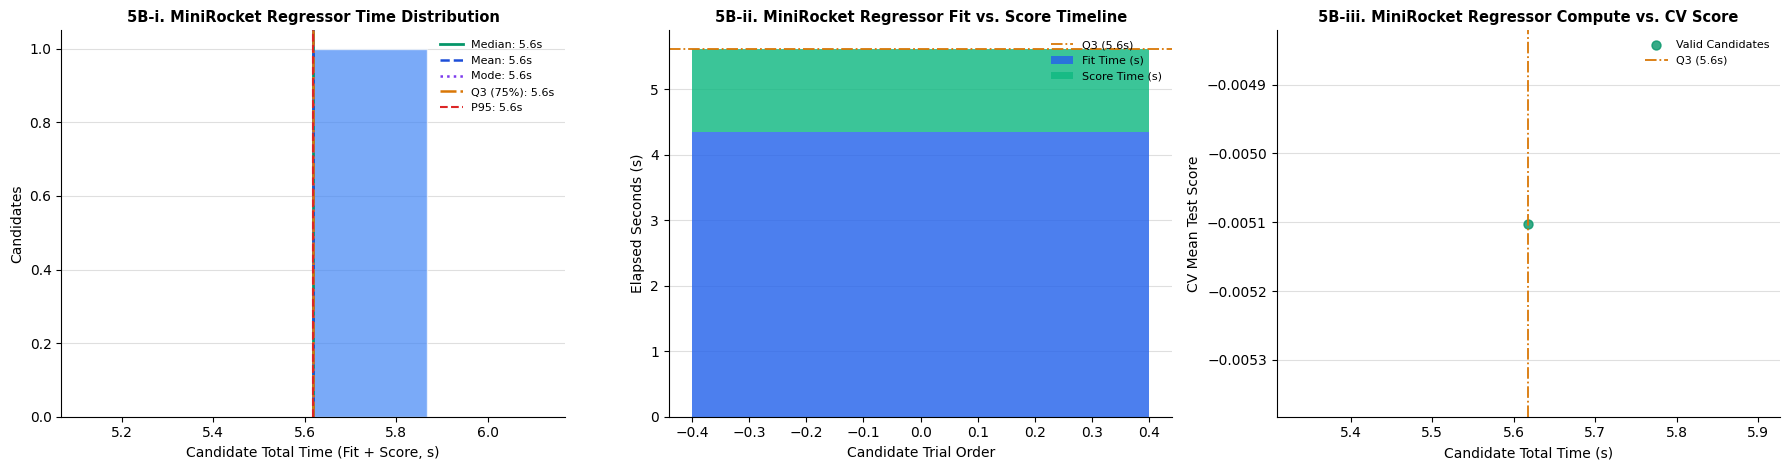

10719

In [28]:
candidate_timing_summary_df = plot_candidate_timing_analysis(
    cv_analysis_artifacts,
    max_candidate_seconds=max_candidate_seconds,
    results_dir=results_dir,
    timestamp=timestamp,
    experiment_name=experiment_name,
    save_results=save_plots,
)
del candidate_timing_summary_df
gc.collect()

## Optional Experiment Tracking (Weights & Biases)

In [29]:
if use_wandb:
    if wandb is None:
        print('Skipping W&B logging: wandb is not installed.')
    else:
        wandb_run = wandb.init(
            project=wandb_project,
            name=experiment_name,
            config={
                'data_version': data_version,
                'era_tag': era_tag,
                'model_tag': model_tag,
                'TARGET_COL': TARGET_COL,
                'feature_set': feature_set,
                'era_stride': era_stride,
                'search_mode': search_mode,
                'cv_strategy': cv_strategy,
                'n_splits': n_splits,
                'cv_split': cv_split,
                'downsample_mode': downsample_mode,
                'downsample_frac': downsample_frac,
                'val_downsample_mode': val_downsample_mode,
                'val_downsample_frac': val_downsample_frac,
                'target_horizon_eras': target_horizon_eras,
                'embargo_eras': embargo_eras,
                'eval_mode': eval_mode,
                'walk_forward_step_eras': walk_forward_step_eras,
                'walk_forward_window': walk_forward_window,
                'era_weighting': era_weighting,
                'recency_decay': recency_decay,
                'random_state': random_state,
                'n_iter': n_iter,
                'verbose': verbose,
                'n_jobs': n_jobs,
                'lgbm_n_jobs': lgbm_n_jobs,
                'error_bin_mode': error_bin_mode,
            },
        )
        log_payload = {
            'comparison_table': wandb.Table(dataframe=comparison_df),
            'search_summary_table': wandb.Table(dataframe=search_summary_df.drop(columns=['best_params'], errors='ignore')),
            'timing/prep_elapsed_s': float(prep_elapsed_s),
            'timing/train_elapsed_s': float(train_elapsed_s),
        }
        for m_name, m_cv_df in cv_analysis_artifacts['top_candidates'].items():
            m_slug = m_name.lower().replace(' ', '_')
            log_payload[f'cv_table/{m_slug}'] = wandb.Table(dataframe=m_cv_df.astype(str))
        for row in search_summary_rows:
            m_slug = row['model'].lower().replace(' ', '_')
            log_payload[f'best_cv_corr/{m_slug}'] = float(row['best_cv_corr'])
        wandb.log(log_payload)
        wandb.finish()
        print('Logged experiment tables and metrics to Weights & Biases.')
else:
    print('W&B tracking disabled (use_wandb=False).')

W&B tracking disabled (use_wandb=False).
